# ETS Praktikum Machine Learning
## Klasifikasi, Regresi, dan Clustering (23 Soal)

| Nama | NRP |
|------|-----|
|Benedictus Ryu Gunawan |5054251001 |

### Petunjuk
1. Bagian **Data Loading**, **EDA**, dan **Preprocessing** pada setiap bagian sudah disediakan. Jalankan saja, jangan diubah.
2. Pada setiap sel **Soal**, ganti `_____` dengan kode yang tepat hingga output sepadan dengan **output referensi**.
3. Gunakan `random_state=RANDOM_STATE` pada setiap model yang memiliki parameter tersebut.
4. Angka pada output referensi bisa sedikit berbeda karena perbedaan versi library.
5. Jalankan sel **Setup** di bawah ini terlebih dahulu, lalu jalankan notebook **berurutan dari atas ke bawah**. Setiap bagian memuat ulang dataset dan melakukan preprocessing sendiri.

### Susunan Soal
| Bagian | Soal | Dataset | File yang diupload |
|--------|------|---------|--------------------|
| A : Klasifikasi | 1–8 (1 soal import + 6 soal model + 1 evaluasi metrik) | IBM HR Analytics Employee Attrition | `HR-Employee-Attrition.csv` |
| B : Regresi | 9–16 (1 soal import + 6 soal model + 1 evaluasi metrik) | Concrete Compressive Strength | `Concrete_Data.csv` |
| C : Clustering | 17–23 (1 soal import + 5 soal model + 1 evaluasi metrik) | Wine Recognition (UCI) | `wine_dataset.csv` |

Upload ketiga file CSV melalui **Add Input → Upload → New Dataset** di Kaggle Notebook.

## Setup : Import Library Umum
Jalankan sel ini sekali di awal. Library model `sklearn` untuk setiap bagian diimport pada soal pertama masing-masing bagian.

In [44]:
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage as hc_linkage, dendrogram

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

---
# Bagian A : Klasifikasi (Soal 1–8)

### Dataset: IBM HR Analytics Employee Attrition
Sumber: https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

Upload `HR-Employee-Attrition.csv` melalui **Add Input → Upload → New Dataset** di Kaggle Notebook.

Target: **Attrition** (1 = karyawan keluar, 0 = bertahan).

## Soal 1 : Import Library Model Klasifikasi
Lengkapi import `sklearn` untuk semua model dan metrik yang dipakai pada Soal 2–8: KNN, Gaussian & Bernoulli Naive Bayes, Logistic Regression, Decision Tree (beserta fungsi visualisasi pohon), SVM, MLP, serta metrik accuracy, precision, recall, F1, dan confusion matrix.

Sel ini tidak menghasilkan output. Jawaban dianggap benar jika sel berjalan tanpa error dan seluruh soal berikutnya pada bagian ini dapat dijalankan.

In [45]:
# K-Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier
# Gaussian Naive Bayes dan Bernoulli Naive Bayes
from sklearn.naive_bayes import GaussianNB, BernoulliNB
# Logistic Regression
from sklearn.linear_model import LogisticRegression
# Decision Tree (model klasifikasi + fungsi visualisasi pohon)
from sklearn.tree import DecisionTreeClassifier, plot_tree
# Support Vector Machine (klasifikasi)
from sklearn.svm import SVC
# Multi-layer Perceptron (klasifikasi)
from sklearn.neural_network import MLPClassifier
# Metrik: accuracy, precision, recall, F1, confusion matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import glob
import pandas as pd

## A.1 Data Loading

In [46]:
DATA_PATH = "/kaggle/input/datasets/farelfebryan/dataset-ets-praktikum-ml-rka-2026/HR_Employee_Attrition.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## A.2 Exploratory Data Analysis

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [48]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [49]:
print('Missing value:', df.isna().sum().sum())
print('Duplikat     :', df.duplicated().sum())
df.nunique().sort_values().head(6)

Missing value: 0
Duplikat     : 0


EmployeeCount        1
Over18               1
StandardHours        1
Attrition            2
OverTime             2
PerformanceRating    2
dtype: int64

`EmployeeCount`, `Over18`, dan `StandardHours` hanya memiliki satu nilai unik, sedangkan `EmployeeNumber` adalah ID. Keempat kolom tersebut tidak informatif.

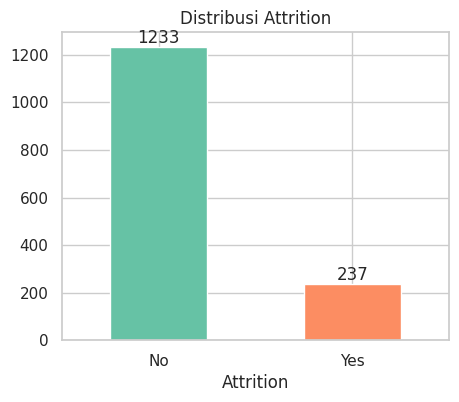

Attrition
No     0.839
Yes    0.161
Name: count, dtype: float64


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

counts = df['Attrition'].value_counts()
ax = counts.plot(kind='bar', color=['#66c2a5', '#fc8d62'], figsize=(5, 4), rot=0)
ax.bar_label(ax.containers[0])
ax.set_title('Distribusi Attrition')
plt.show()
print((counts / counts.sum()).round(3))

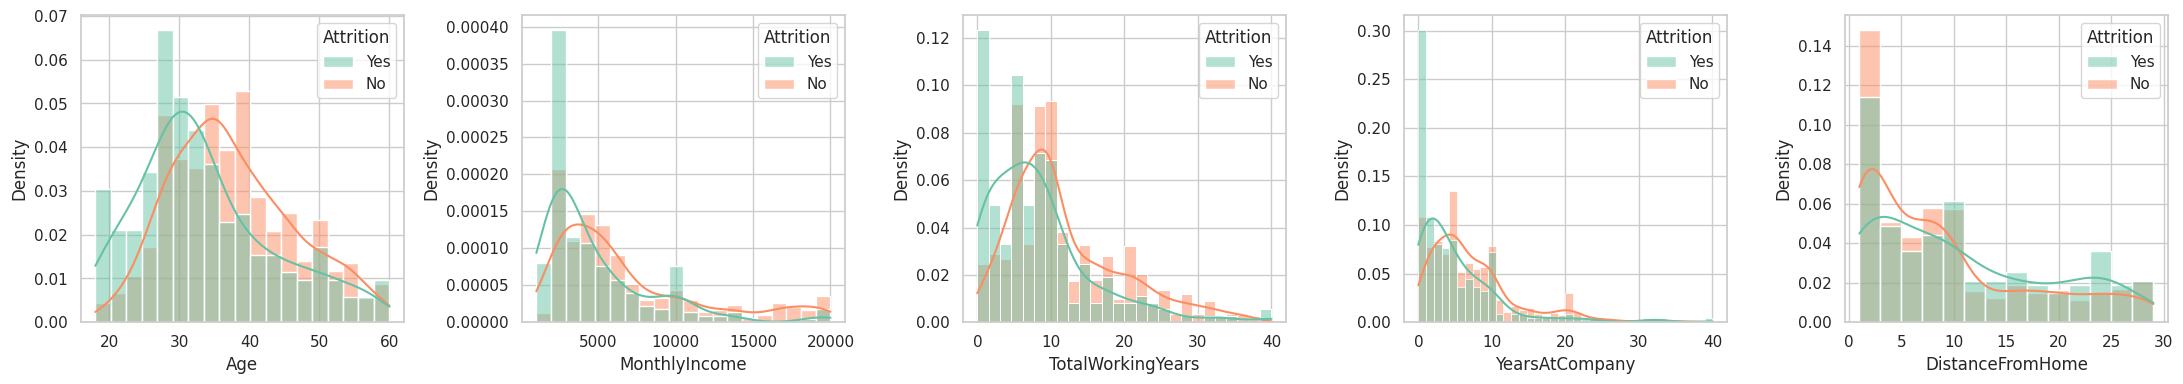

In [51]:
num_show = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'DistanceFromHome']
fig, axes = plt.subplots(1, len(num_show), figsize=(22, 4))
for ax, col in zip(axes, num_show):
    sns.histplot(data=df, x=col, hue='Attrition', kde=True, stat='density', common_norm=False,
                 palette='Set2', ax=ax)
plt.tight_layout()
plt.show()

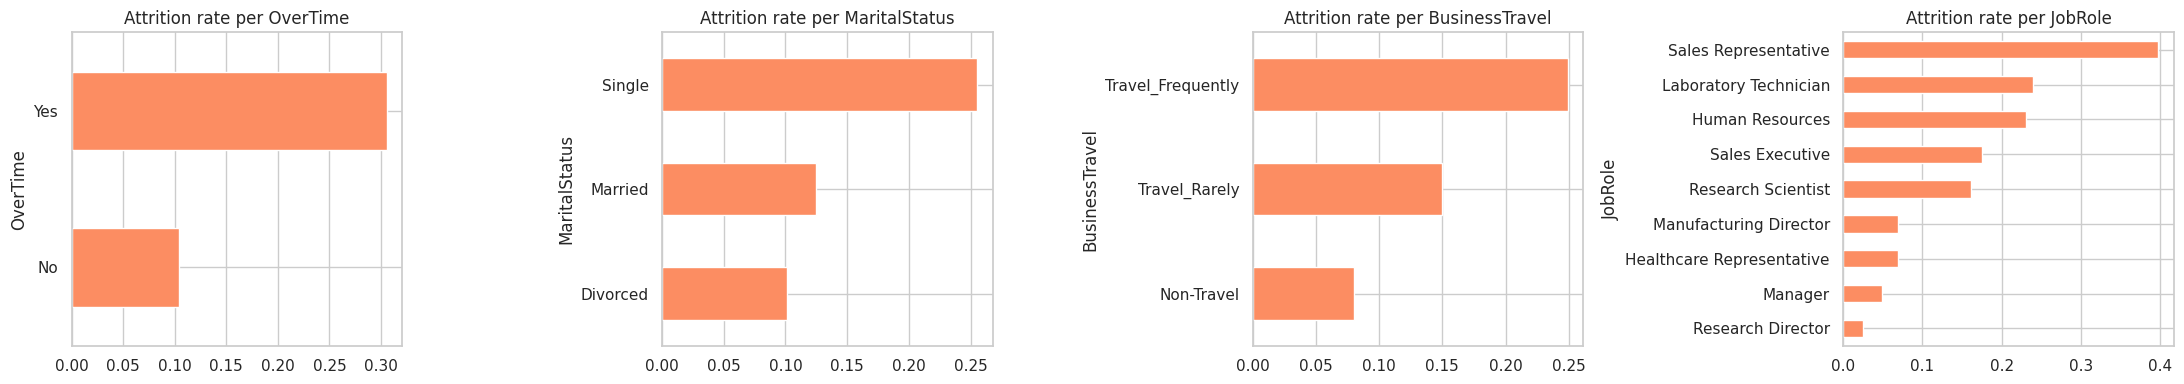

In [52]:
cat_show = ['OverTime', 'MaritalStatus', 'BusinessTravel', 'JobRole']
fig, axes = plt.subplots(1, len(cat_show), figsize=(22, 4))
for ax, col in zip(axes, cat_show):
    rate = df.groupby(col)['Attrition'].apply(lambda s: (s == 'Yes').mean()).sort_values()
    rate.plot(kind='barh', ax=ax, color='#fc8d62')
    ax.set_title(f'Attrition rate per {col}')
plt.tight_layout()
plt.show()

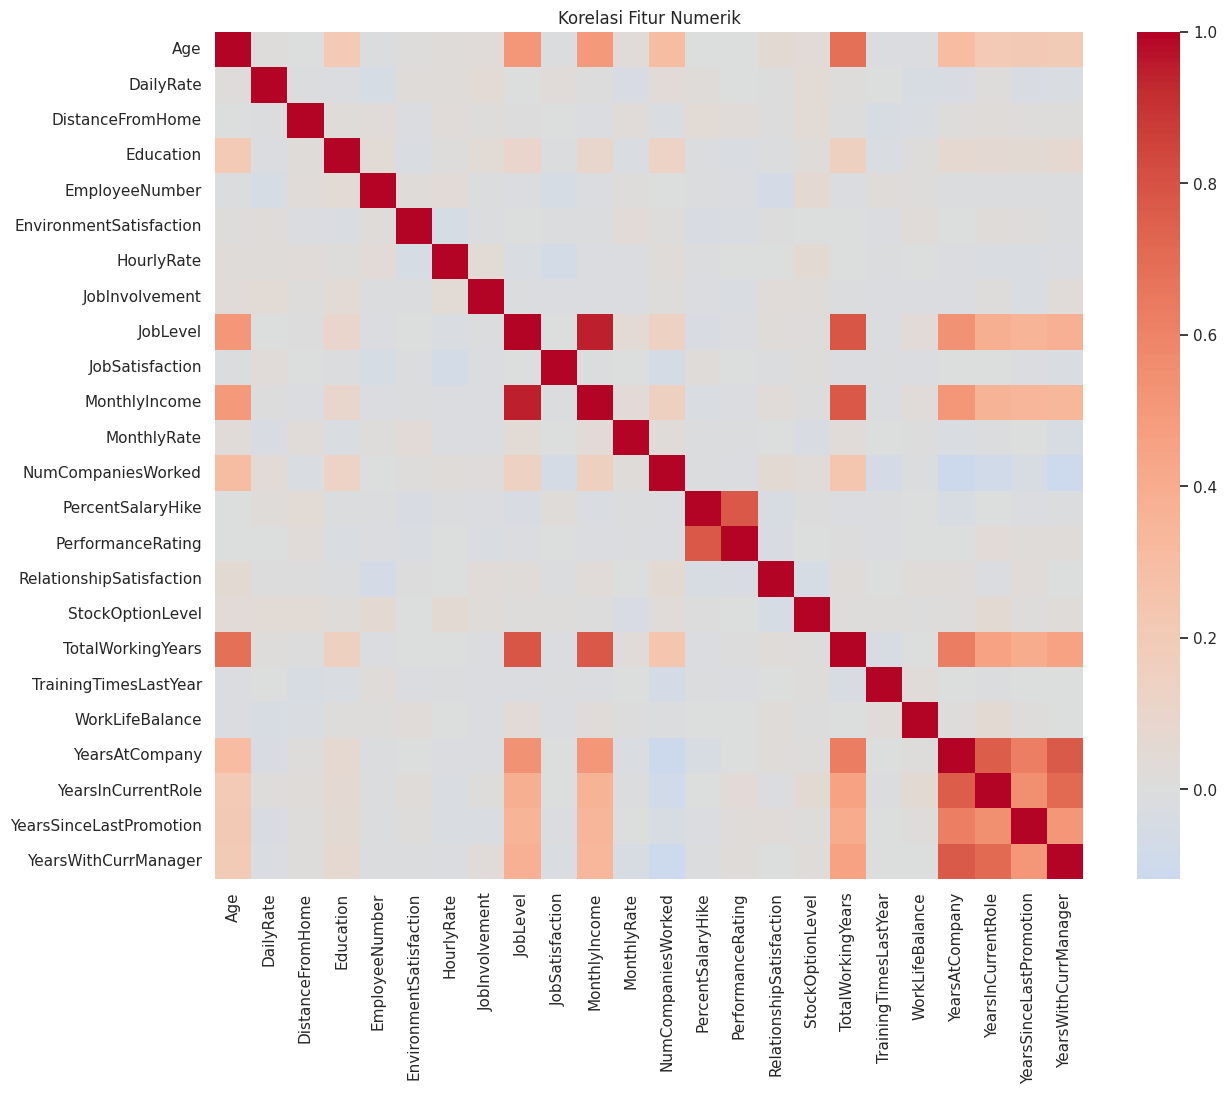

In [53]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.select_dtypes('number').drop(columns=['EmployeeCount', 'StandardHours']).corr(),
            cmap='coolwarm', center=0)
plt.title('Korelasi Fitur Numerik')
plt.show()

## A.3 Preprocessing

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
RANDOM_STATE = 42

df_clean = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])
df_clean['Attrition'] = (df_clean['Attrition'] == 'Yes').astype(int)

cat_cols = df_clean.select_dtypes('object').columns.tolist()
X = pd.get_dummies(df_clean.drop(columns='Attrition'), columns=cat_cols, drop_first=True, dtype=int)
y = df_clean['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

feature_names = X.columns.tolist()
class_names = ['Stay', 'Leave']
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1176, 44) | Test: (294, 44)


| Variabel | Isi | Dipakai untuk |
|----------|-----|---------------|
| `X_train`, `X_test` | Fitur ter-*encode*, **tanpa scaling** | Decision Tree |
| `X_train_scaled`, `X_test_scaled` | Fitur ter-*encode* + StandardScaler | KNN, Naive Bayes, Logistic Regression, SVM, MLP |
| `y_train`, `y_test` | Label target | Semua model |
| `feature_names`, `class_names` | Nama fitur & kelas | Visualisasi |

## A.4 Soal Klasifikasi

## Soal 2 : KNN: Nilai K dan Distance Metric
Lengkapi kode untuk melatih `KNeighborsClassifier` dengan setiap kombinasi `n_neighbors` dan `metric`, lalu hitung akurasi test.

**Output referensi:**

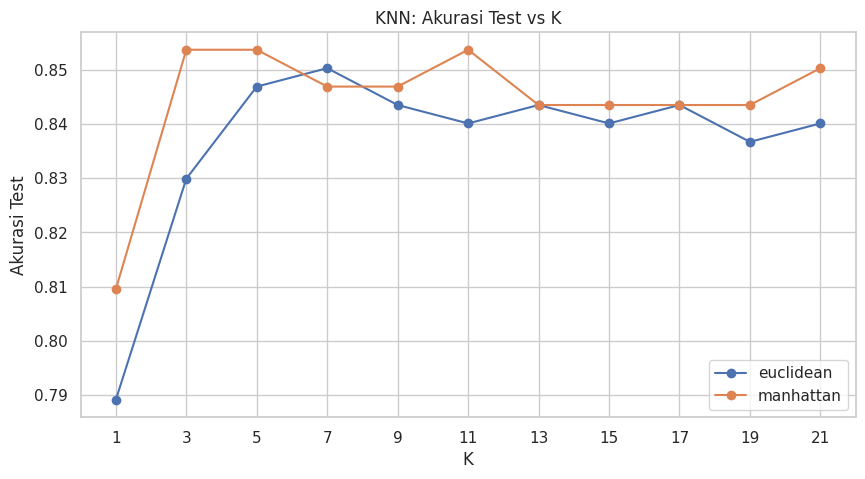

```
    euclidean  manhattan
1      0.7891     0.8095
3      0.8299     0.8537
5      0.8469     0.8537
7      0.8503     0.8469
9      0.8435     0.8469
11     0.8401     0.8537
13     0.8435     0.8435
15     0.8401     0.8435
17     0.8435     0.8435
19     0.8367     0.8435
21     0.8401     0.8503
```

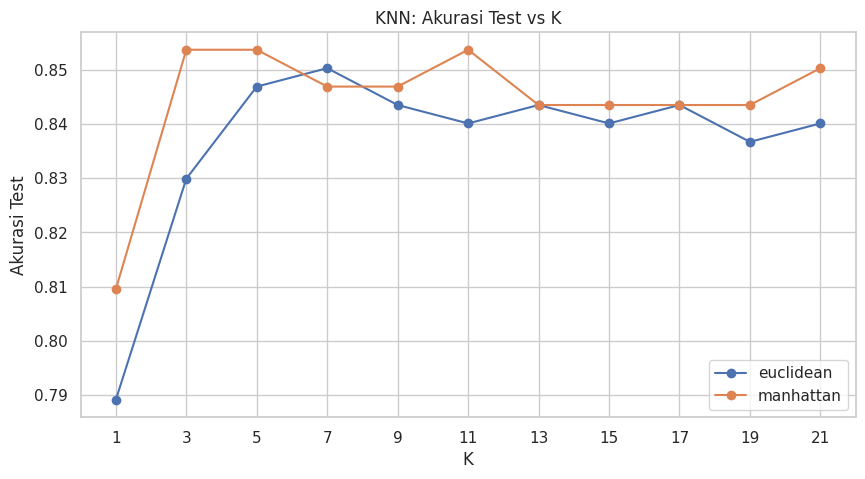

,euclidean,manhattan
1,0.7891,0.8095
3,0.8299,0.8537
5,0.8469,0.8537
7,0.8503,0.8469
9,0.8435,0.8469
11,0.8401,0.8537
13,0.8435,0.8435
15,0.8401,0.8435
17,0.8435,0.8435
19,0.8367,0.8435


In [55]:
k_values = list(range(1, 22, 2))
knn_scores = {'euclidean': [], 'manhattan': []}
for metric in knn_scores:
    for k in k_values:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
        knn.fit(X_train_scaled, y_train)
        knn_scores[metric].append(accuracy_score( knn.predict(X_test_scaled) , y_test))

plt.figure(figsize=(10, 5))
for metric, scores in knn_scores.items():
    plt.plot(k_values, scores, marker='o', label=metric)
plt.xticks(k_values)
plt.xlabel('K')
plt.ylabel('Akurasi Test')
plt.title('KNN: Akurasi Test vs K')
plt.legend()
plt.show()
pd.DataFrame(knn_scores, index=k_values).round(4)

## Soal 3 : Naive Bayes: Gaussian vs Bernoulli
Lengkapi kode untuk melatih kedua varian Naive Bayes pada data yang sudah discaling, lalu hitung accuracy dan recall.

**Output referensi:**

```
         model  accuracy  recall
0   GaussianNB    0.6156  0.7021
1  BernoulliNB    0.8095  0.4681
```

In [56]:
nb_models = {'GaussianNB': GaussianNB(), 'BernoulliNB': BernoulliNB()}
nb_rows = []
for name, model in nb_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    nb_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test,y_pred),
        'recall': recall_score(y_test,y_pred),
    })
pd.DataFrame(nb_rows).round(4)

,model,accuracy,recall
0,GaussianNB,0.6156,0.7021
1,BernoulliNB,0.8095,0.4681


## Soal 4 : Logistic Regression: Regularisasi C dan Class Weight
Lengkapi kode untuk melatih `LogisticRegression` (`max_iter=1000`) dengan setiap kombinasi `C` dan `class_weight`.

**Output referensi:**

```
  class_weight      C  accuracy  recall      f1
0         None   0.01    0.8571  0.1277  0.2222
1         None   0.10    0.8639  0.3404  0.4444
2         None   1.00    0.8605  0.3404  0.4384
3         None  10.00    0.8571  0.3404  0.4324
4     balanced   0.01    0.7857  0.7021  0.5116
5     balanced   0.10    0.7653  0.6596  0.4733
6     balanced   1.00    0.7517  0.6170  0.4427
7     balanced  10.00    0.7449  0.5957  0.4275
```

In [57]:
lr_rows = []
for class_weight in [None, "balanced"]:
    for C in [0.01,0.1,1,10]:
        lr = LogisticRegression(max_iter=1000, C=C, class_weight=class_weight)
        lr.fit(X_train_scaled, y_train)
        y_pred = lr.predict(X_test_scaled)
        lr_rows.append({
            'class_weight': class_weight,
            'C': C,
            'accuracy': accuracy_score(y_test,y_pred),
            'recall': recall_score(y_test,y_pred),
            'f1': f1_score(y_test,y_pred),
        })
pd.DataFrame(lr_rows).round(4)

,class_weight,C,accuracy,recall,f1
0,None,0.01,0.8571,0.1277,0.2222
1,None,0.10,0.8639,0.3404,0.4444
2,None,1.00,0.8605,0.3404,0.4384
3,None,10.00,0.8571,0.3404,0.4324
4,balanced,0.01,0.7857,0.7021,0.5116
5,balanced,0.10,0.7653,0.6596,0.4733
6,balanced,1.00,0.7517,0.6170,0.4427
7,balanced,10.00,0.7449,0.5957,0.4275


## Soal 5 : Decision Tree
Lengkapi kode sehingga menghasilkan pohon **persis** seperti gambar referensi. Perhatikan kriteria impurity pada setiap node dan kedalaman pohon. Gunakan `X_train` (tanpa scaling).

**Output referensi:**

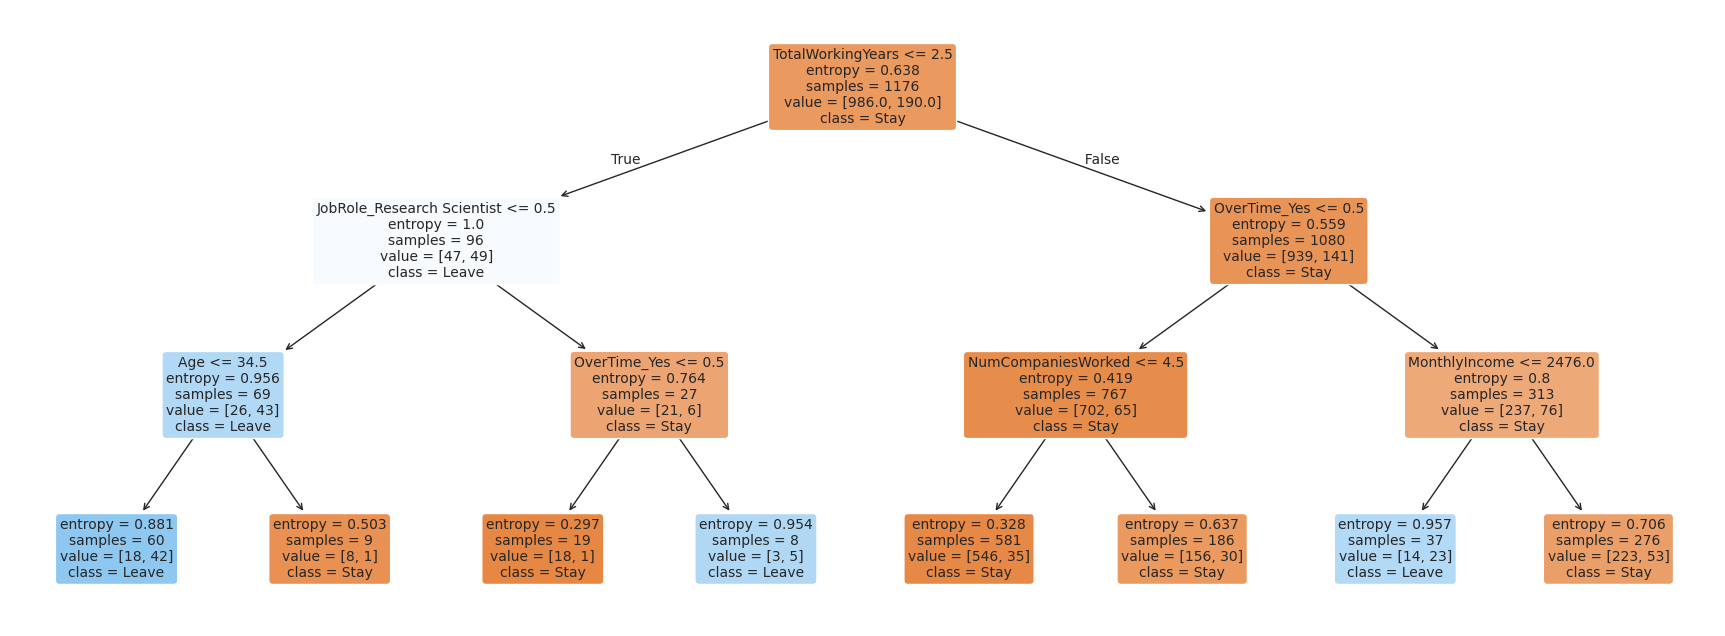

```
Akurasi train = 0.8682 | Akurasi test = 0.8299
```

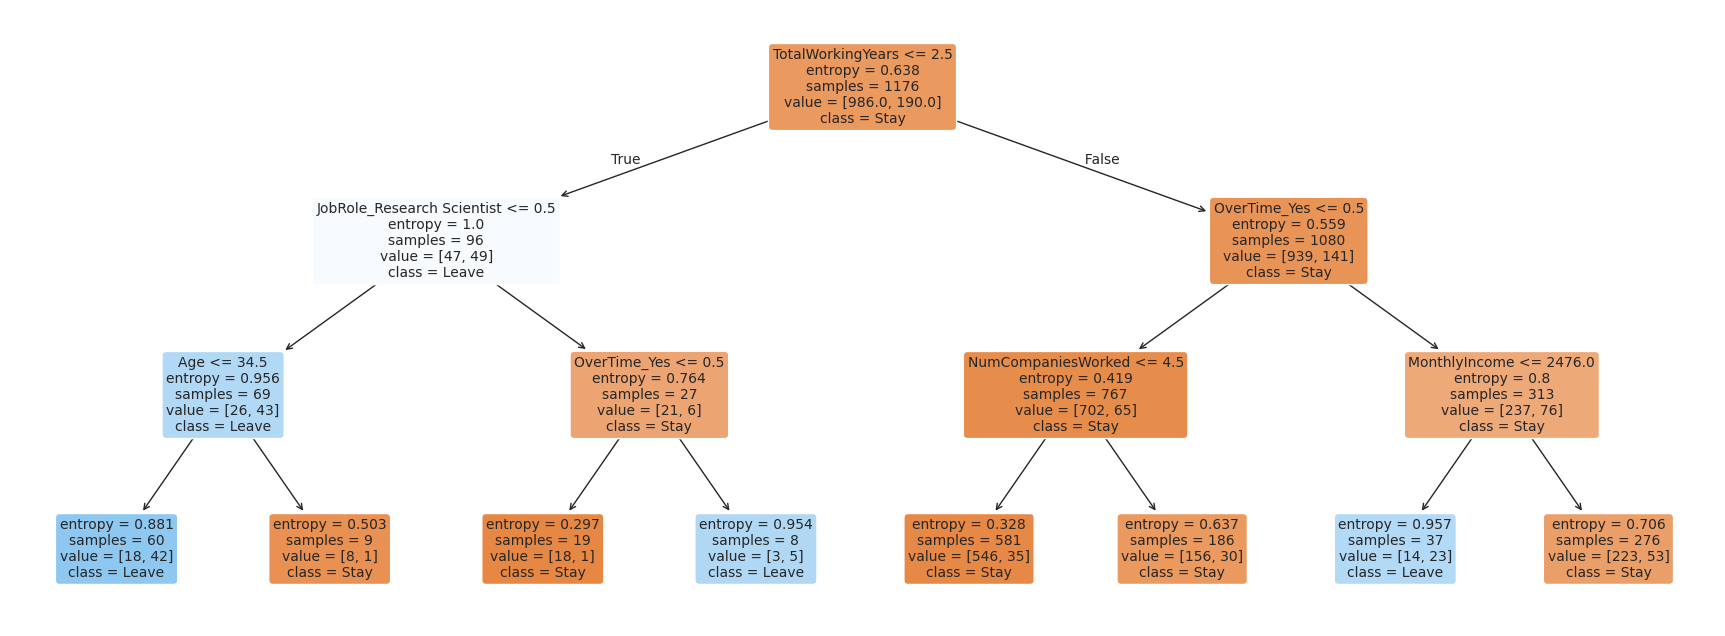

Akurasi train = 0.8682 | Akurasi test = 0.8299


In [58]:
dt_model = DecisionTreeClassifier(min_samples_split=5, max_depth=3, criterion="entropy", random_state=RANDOM_STATE)
dt_model.fit(X_train, y_train)

plt.figure(figsize=(22, 8))

#PLOT HASIL TREE
plot_tree(dt_model, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=10)

plt.show()
print(f'Akurasi train = {dt_model.score(X_train, y_train):.4f} | Akurasi test = {dt_model.score(X_test, y_test):.4f}')

## Soal 6 : SVM: Perbandingan Kernel
Lengkapi kode untuk melatih `SVC` (`C=1`) dengan setiap kernel, lalu catat akurasi test dan jumlah support vector.

**Output referensi:**

```
    kernel  accuracy  jumlah_SV
0   linear    0.8673        345
1     poly    0.8469        628
2      rbf    0.8673        545
3  sigmoid    0.8741        379
```

In [59]:
svm_rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    svm = SVC(C=1,kernel=kernel)
    svm.fit(X_train_scaled,y_train)
    y_pred = svm.predict(X_test_scaled)
    svm_rows.append({
        "kernel": kernel,
        "accuracy": accuracy_score(y_test,y_pred),
        "jumlah_SV": len(svm.support_vectors_),
    })
pd.DataFrame(svm_rows).round(4)

,kernel,accuracy,jumlah_SV
0,linear,0.8673,345
1,poly,0.8469,628
2,rbf,0.8673,545
3,sigmoid,0.8741,379


## Soal 7 : ANN (MLP): Ukuran Arsitektur
Lengkapi kode untuk melatih `MLPClassifier` (`activation='relu'`, `max_iter=300`) dengan setiap arsitektur, lalu plot *loss curve*-nya.

**Output referensi:**

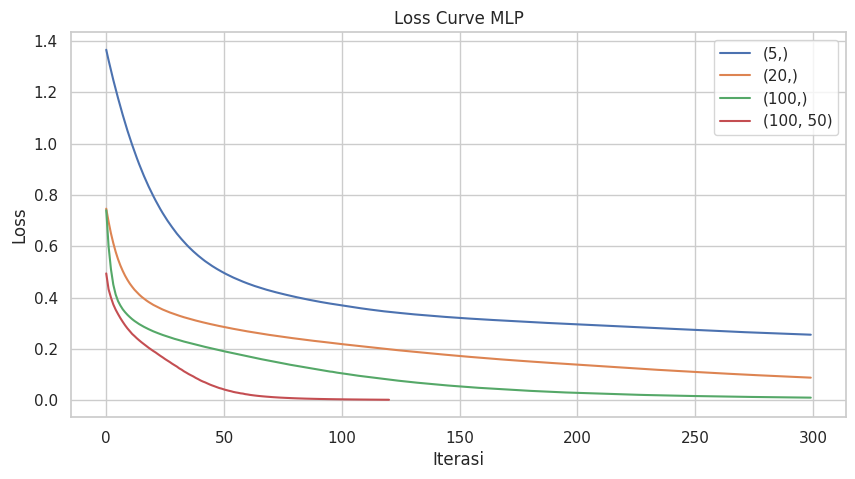

```
  arsitektur  train_acc  test_acc
0       (5,)     0.9065    0.8571
1      (20,)     0.9770    0.8333
2     (100,)     1.0000    0.8231
3  (100, 50)     1.0000    0.8231
```

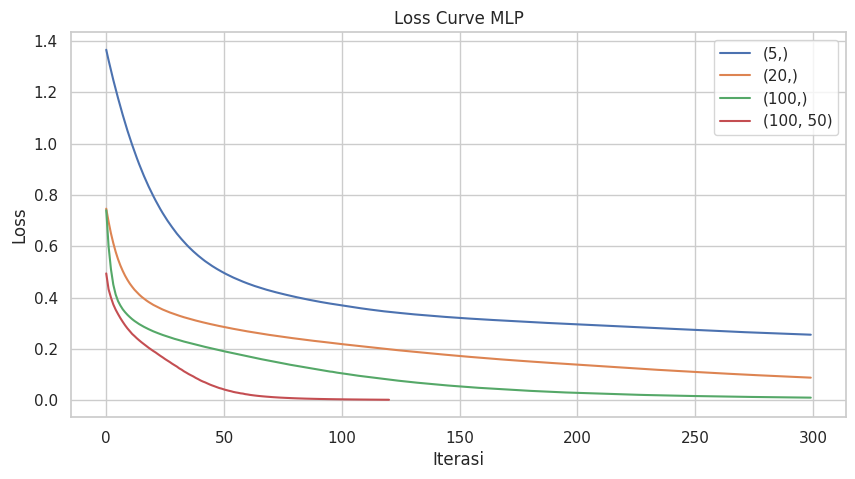

,arsitektur,train_acc,test_acc
0,"(5,)",0.9065,0.8571
1,"(20,)",0.9770,0.8333
2,"(100,)",1.0000,0.8231
3,"(100, 50)",1.0000,0.8231


In [60]:
mlp_rows = []
plt.figure(figsize=(10, 5))
for arch in [(5,), (20,), (100,), (100,50)]:
    mlp = MLPClassifier(hidden_layer_sizes=arch, max_iter=300, activation='relu', random_state=RANDOM_STATE)
    mlp.fit(X_train_scaled, y_train)
    y_pred = mlp.predict(X_test_scaled)
    mlp_rows.append({
        'arsitektur': str(arch),
        'train_acc': accuracy_score(y_train, mlp.predict(X_train_scaled)),
        'test_acc': accuracy_score(y_test,y_pred),
    })
    plt.plot(mlp.loss_curve_, label=str(arch))
plt.xlabel('Iterasi')
plt.ylabel('Loss')
plt.title('Loss Curve MLP')
plt.legend()
plt.show()
pd.DataFrame(mlp_rows).round(4)

## Soal 8 : Evaluasi Metrik Klasifikasi
Lengkapi kode untuk membuat *confusion matrix* dan menghitung accuracy, precision, recall, serta F1-score dari ketiga model berikut.

**Output referensi:**

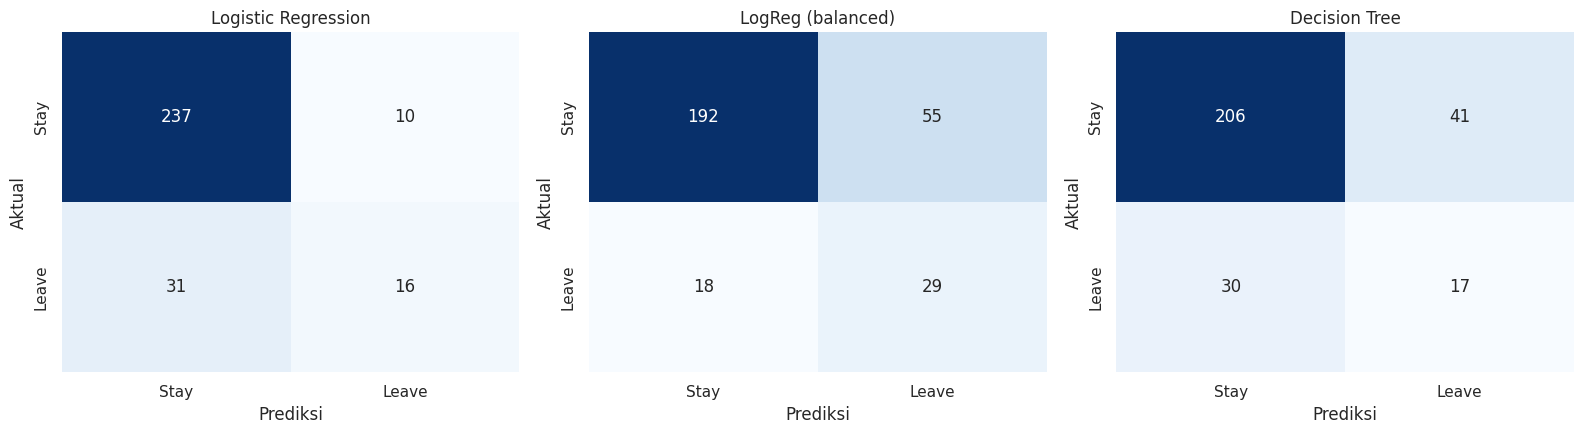

```
                 model  accuracy  precision  recall      f1
0  Logistic Regression    0.8605     0.6154  0.3404  0.4384
1    LogReg (balanced)    0.7517     0.3452  0.6170  0.4427
2        Decision Tree    0.7585     0.2931  0.3617  0.3238
```

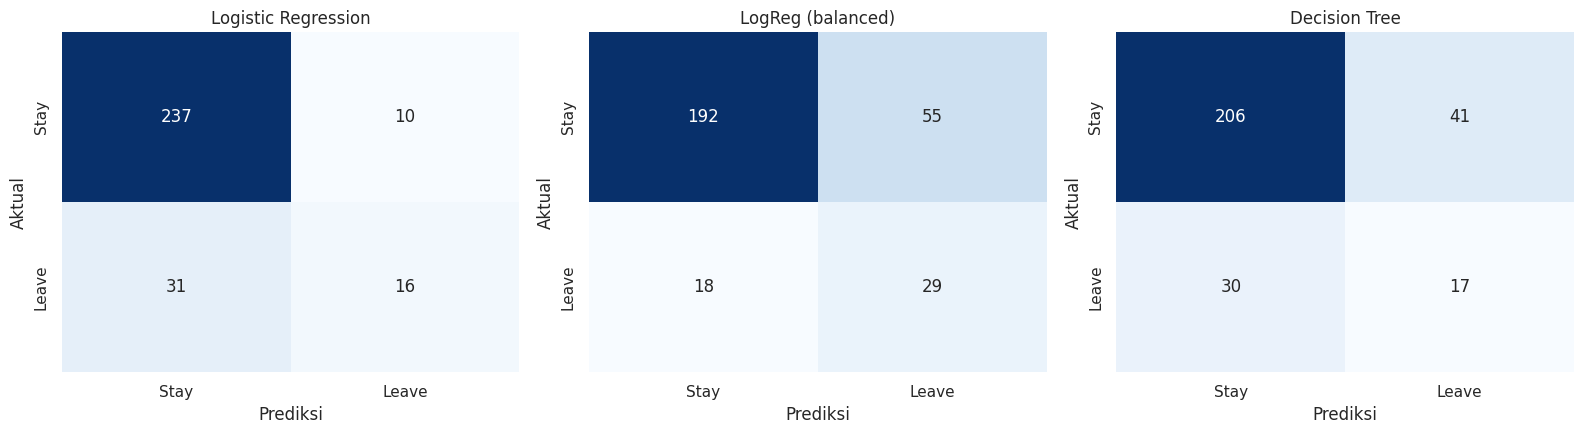

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384
1,LogReg (balanced),0.7517,0.3452,0.6170,0.4427
2,Decision Tree,0.7585,0.2931,0.3617,0.3238


In [61]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LogReg (balanced)': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
}

metric_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test,y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(name)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    metric_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test,y_pred),
        'precision': precision_score(y_test,y_pred),
        'recall': recall_score(y_test,y_pred),
        'f1': f1_score(y_test,y_pred),
    })
plt.tight_layout()
plt.show()
pd.DataFrame(metric_rows).round(4)

---
# Bagian B : Regresi (Soal 9–16)

### Dataset: Concrete Compressive Strength
Sumber: https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength
(Yeh, I-C. 1998. *Modeling of strength of high-performance concrete using artificial neural networks*. Cement and Concrete Research, 28(12), 1797–1808.)

Upload `Concrete_Data.csv` melalui **Add Input → Upload → New Dataset** di Kaggle Notebook.

Target: **strength** (kuat tekan beton dalam MPa, bernilai kontinu). Data berisi **1.030 sampel** campuran beton dengan **8 fitur** dan **1 target**, semuanya numerik dan tanpa missing value.

| No | Kolom asli pada file | Nama di notebook | Satuan | Peran | Rentang | Penjelasan |
|----|----------------------|------------------|--------|-------|---------|------------|
| 1 | Cement (component 1) | `cement` | kg/m³ campuran | Fitur | 102 – 540 | Semen, bahan pengikat utama beton. |
| 2 | Blast Furnace Slag (component 2) | `slag` | kg/m³ campuran | Fitur | 0 – 359,4 | Terak tanur tinggi, limbah pembuatan baja yang dipakai sebagai pengganti sebagian semen. |
| 3 | Fly Ash (component 3) | `fly_ash` | kg/m³ campuran | Fitur | 0 – 200,1 | Abu terbang, sisa pembakaran batu bara yang bersifat semen jika bereaksi dengan air. |
| 4 | Water (component 4) | `water` | kg/m³ campuran | Fitur | 121,75 – 247 | Air pencampur. Semakin banyak air, beton umumnya semakin lemah. |
| 5 | Superplasticizer (component 5) | `superplasticizer` | kg/m³ campuran | Fitur | 0 – 32,2 | Bahan tambah kimia yang mengurangi kebutuhan air agar adukan tetap mudah dikerjakan. |
| 6 | Coarse Aggregate (component 6) | `coarse_agg` | kg/m³ campuran | Fitur | 801 – 1145 | Agregat kasar (kerikil atau batu pecah). |
| 7 | Fine Aggregate (component 7) | `fine_agg` | kg/m³ campuran | Fitur | 594 – 992,6 | Agregat halus (pasir). |
| 8 | Age | `age` | hari | Fitur | 1 – 365 | Umur beton saat diuji kuat tekannya. |
| 9 | Concrete compressive strength | `strength` | MPa | **Target** | 2,33 – 82,6 | Kuat tekan beton hasil uji laboratorium. |


## Soal 9 : Import Library Model Regresi
Lengkapi import `sklearn` untuk semua komponen yang dipakai pada Soal 10–16: Polynomial Features, pipeline, Linear/Ridge/Lasso Regression, Decision Tree Regressor (beserta fungsi visualisasi pohon), SVR, serta metrik MAE, MSE, dan R².

Sel ini tidak menghasilkan output. Jawaban dianggap benar jika sel berjalan tanpa error dan seluruh soal berikutnya pada bagian ini dapat dijalankan.

In [62]:
# Polynomial features dan pembuat pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
# Linear Regression, Ridge, Lasso
from sklearn.linear_model import LinearRegression, Ridge, Lasso
# Decision Tree (model regresi + fungsi visualisasi pohon)
from sklearn.tree import DecisionTreeRegressor, plot_tree
# Support Vector Regression
from sklearn.svm import SVR
# Metrik: MAE, MSE, R2
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## B.1 Data Loading

In [63]:
DATA_PATH = '/kaggle/input/datasets/farelfebryan/dataset-ets-praktikum-ml-rka-2026/Concrete_Data.csv'
df = pd.read_csv(DATA_PATH)

# Nama kolom asli panjang, disingkat sesuai tabel dataset di atas
df.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
              'coarse_agg', 'fine_agg', 'age', 'strength']
print(df.shape)
df.head()

(1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## B.2 Exploratory Data Analysis

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [65]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_agg,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_agg,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
strength,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


In [66]:
print('Missing value:', df.isna().sum().sum())
print('Duplikat     :', df.duplicated().sum())
df.nunique().sort_values().head(9)

Missing value: 0
Duplikat     : 25


age                  14
superplasticizer    155
fly_ash             163
slag                187
water               205
cement              280
coarse_agg          284
fine_agg            304
strength            938
dtype: int64

Tidak ada missing value, tetapi terdapat baris duplikat. Baris duplikat akan dibuang pada tahap preprocessing.

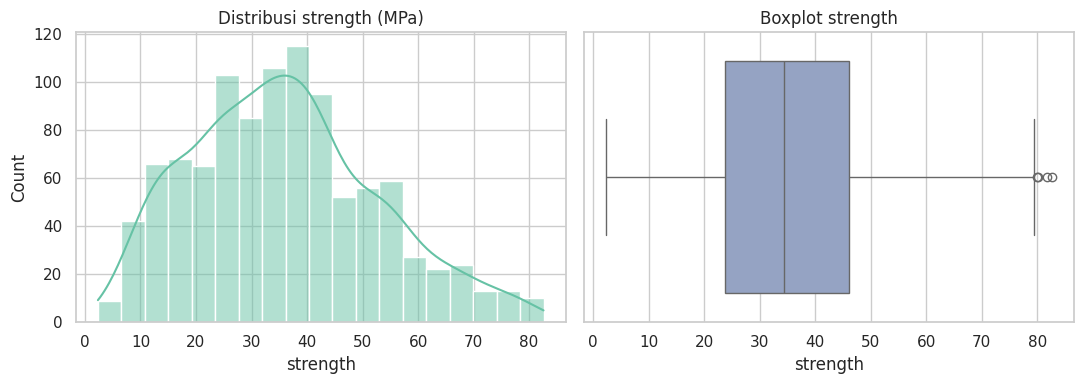

count    1030.00
mean       35.82
std        16.71
min         2.33
25%        23.71
50%        34.44
75%        46.14
max        82.60
Name: strength, dtype: float64


In [67]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['strength'], kde=True, color='#66c2a5', ax=axes[0])
axes[0].set_title('Distribusi strength (MPa)')
sns.boxplot(x=df['strength'], color='#8da0cb', ax=axes[1])
axes[1].set_title('Boxplot strength')
plt.tight_layout()
plt.show()
print(df['strength'].describe().round(2))

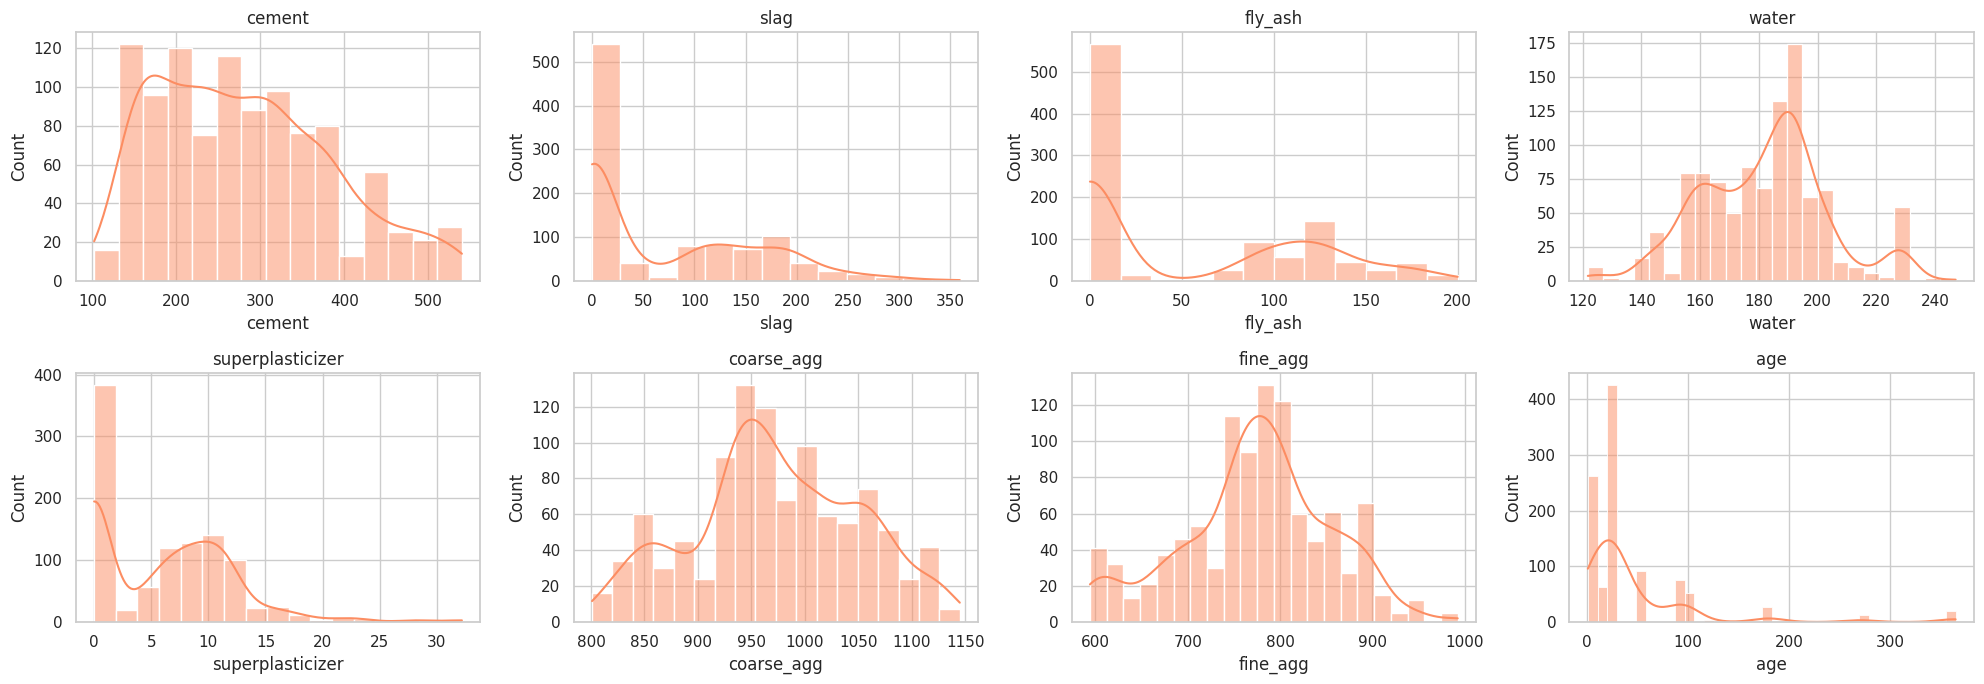

In [68]:
feat_cols = [c for c in df.columns if c != 'strength']
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.histplot(df[col], kde=True, color='#fc8d62', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

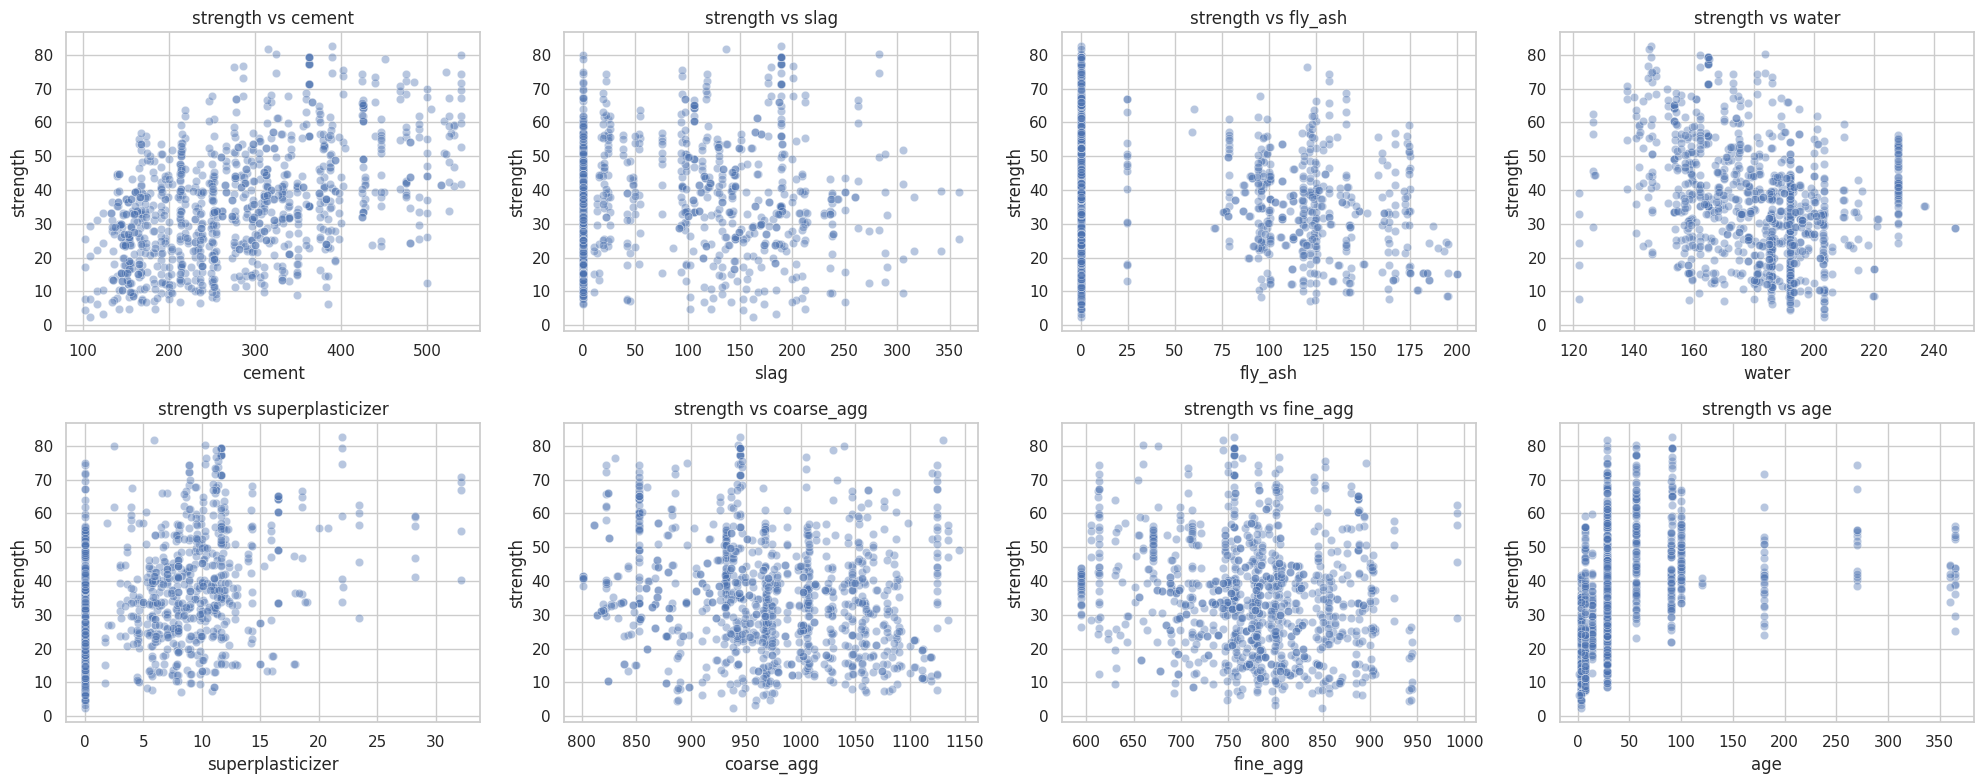

In [69]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.scatterplot(data=df, x=col, y='strength', alpha=0.4, ax=ax)
    ax.set_title(f'strength vs {col}')
plt.tight_layout()
plt.show()

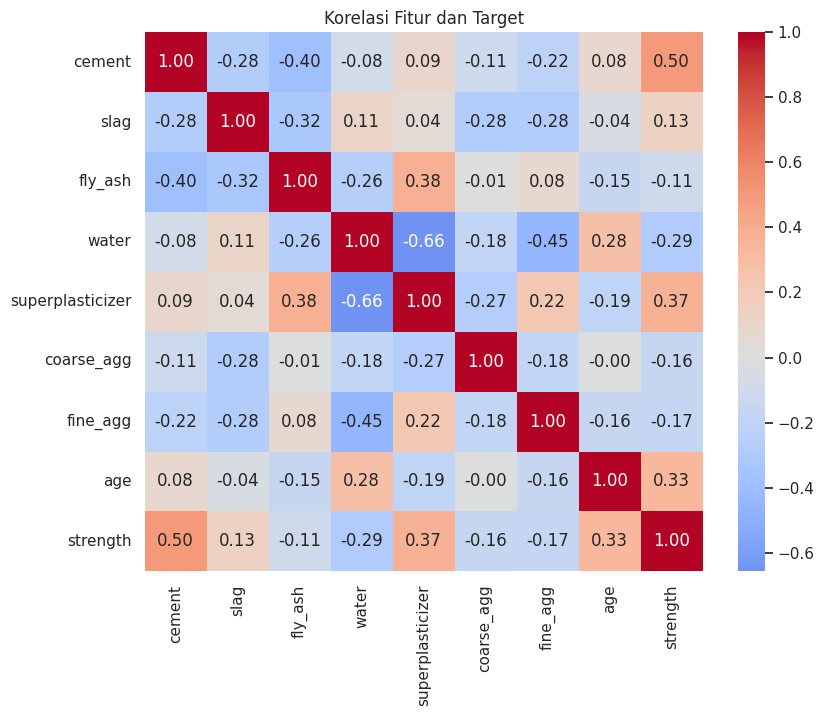

In [70]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korelasi Fitur dan Target')
plt.show()

Hubungan `strength` dengan fitur-fiturnya **tidak sepenuhnya linear**. Contohnya `age` yang kuat tekannya naik cepat di awal lalu melandai. Korelasi antarfitur juga ada, misalnya `water` dengan `superplasticizer`. Hal ini yang akan dieksplorasi pada soal-soal berikut.

## B.3 Preprocessing

In [71]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print('Sebelum:', df.shape, '| Sesudah drop duplikat:', df_clean.shape)

X = df_clean.drop(columns='strength')
y = df_clean['strength']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

feature_names = X.columns.tolist()
print('Train:', X_train.shape, '| Test:', X_test.shape)

Sebelum: (1030, 9) | Sesudah drop duplikat: (1005, 9)
Train: (804, 8) | Test: (201, 8)


| Variabel | Isi | Dipakai untuk |
|----------|-----|---------------|
| `X_train`, `X_test` | Fitur **tanpa scaling** | Decision Tree |
| `X_train_scaled`, `X_test_scaled` | Fitur + StandardScaler | Linear, Polynomial, Ridge, Lasso, SVR |
| `y_train`, `y_test` | Nilai target `strength` | Semua model |
| `feature_names` | Nama fitur | Visualisasi |


## B.4 Soal Regresi

## Soal 10 : Linear Regression
Lengkapi kode untuk melatih `LinearRegression` pada data yang sudah discaling, memprediksi data test, lalu menghitung MAE, RMSE, dan R². Plot actual vs predicted dan tabel koefisien sudah disediakan.

**Output referensi:**

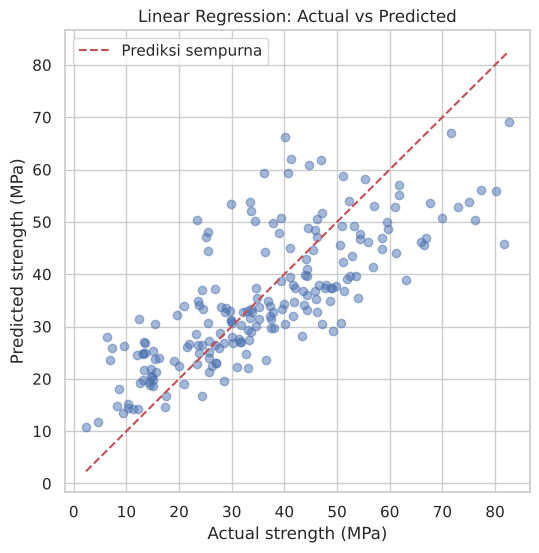

```
MAE          8.8960
RMSE        11.1922
R2 train     0.6098
R2 test      0.5801
dtype: float64

water               -2.835
coarse_agg           1.195
fine_agg             1.667
superplasticizer     1.962
fly_ash              5.440
age                  6.895
slag                 8.436
cement              12.117
dtype: float64
```

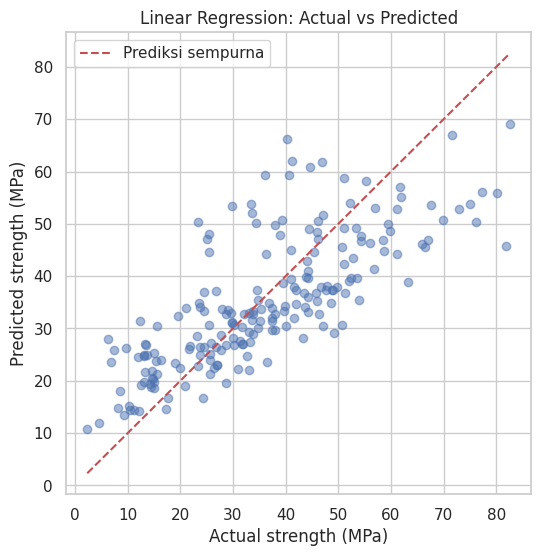

MAE          8.8960
RMSE        11.1922
R2 train     0.6098
R2 test      0.5801
dtype: float64


water               -2.835
coarse_agg           1.195
fine_agg             1.667
superplasticizer     1.962
fly_ash              5.440
age                  6.895
slag                 8.436
cement              12.117
dtype: float64

In [72]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred = lin_reg.predict(X_test_scaled)

metrics_lin = pd.Series({
    'MAE': mean_absolute_error(y_test,y_pred),
    'RMSE': mean_squared_error(y_test,y_pred)**0.5,
    'R2 train': r2_score(y_train,lin_reg.predict(X_train_scaled)),
    'R2 test': r2_score(y_test,y_pred),
}).round(4)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', label='Prediksi sempurna')
plt.xlabel('Actual strength (MPa)')
plt.ylabel('Predicted strength (MPa)')
plt.title('Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

print(metrics_lin)
pd.Series(lin_reg.coef_, index=feature_names).sort_values().round(3)

## Soal 11 : Polynomial Regression: Pengaruh Degree
Lengkapi kode untuk melatih *pipeline* `PolynomialFeatures(degree)` + `LinearRegression` untuk `degree` 1 sampai 4 pada data yang sudah discaling. Catat jumlah fitur hasil transformasi serta R² train dan test, lalu amati kapan model mulai *overfitting*.

**Output referensi:**

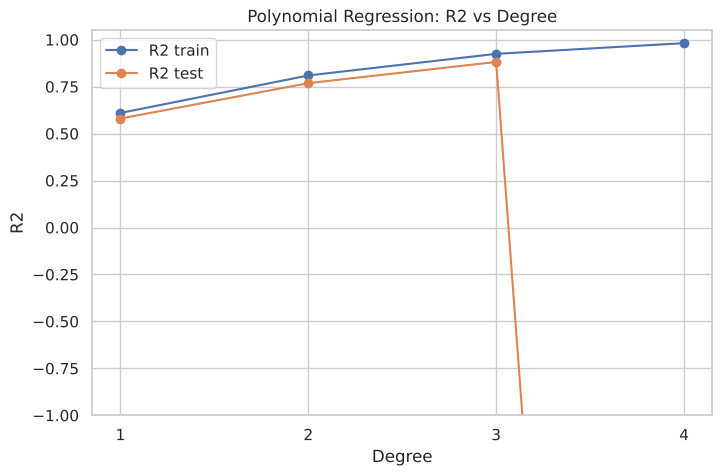

```
   degree  n_fitur  R2 train  R2 test
0       1        9    0.6098   0.5801
1       2       45    0.8095   0.7686
2       3      165    0.9247   0.8814
3       4      495    0.9816 -12.6022
```

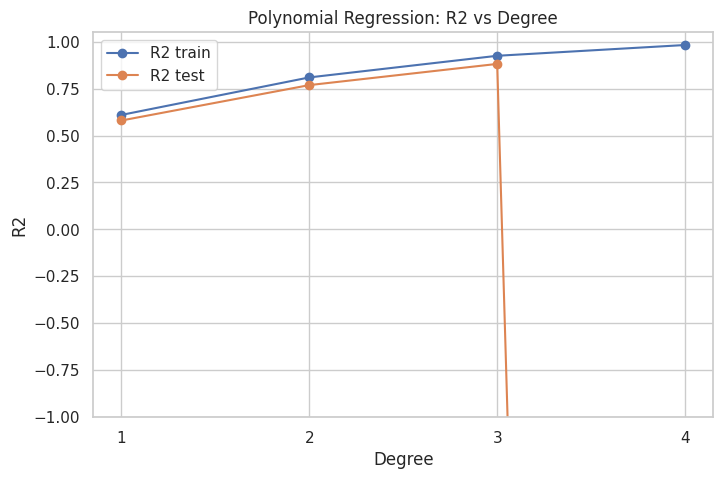

,degree,n_fitur,R2 train,R2 test
0,1,9,0.6098,0.5801
1,2,45,0.8095,0.7686
2,3,165,0.9247,0.8814
3,4,495,0.9821,-33.1951


In [73]:
poly_rows = []
for degree in range(1,5):
    poly_model = Pipeline(
        [
            ("poly", PolynomialFeatures(degree)),
            ("model", LinearRegression())
        ]
    )
    poly_model.fit(X_train_scaled,y_train)
    y_pred = poly_model.predict(X_test_scaled)
    poly_rows.append({
        'degree': degree,
        'n_fitur': poly_model.fit(X_train_scaled,y_train)[:-1].transform(X_train_scaled).shape[1],
        'R2 train': r2_score(y_train , poly_model.predict(X_train_scaled)),
        'R2 test': r2_score(y_test , y_pred),
    })
poly_df = pd.DataFrame(poly_rows)

plt.figure(figsize=(8, 5))
plt.plot(poly_df['degree'], poly_df['R2 train'], marker='o', label='R2 train')
plt.plot(poly_df['degree'], poly_df['R2 test'], marker='o', label='R2 test')
plt.ylim(-1, 1.05)   # R2 test degree 4 sangat negatif, sumbu y dipotong agar kurva lain terlihat
plt.xticks(poly_df['degree'])
plt.xlabel('Degree')
plt.ylabel('R2')
plt.title('Polynomial Regression: R2 vs Degree')
plt.legend()
plt.show()
poly_df.round(4)

## Soal 12 : Ridge Regression: Pengaruh Alpha
Fitur polynomial `degree=3` sudah disediakan. Lengkapi kode untuk melatih `Ridge` dengan setiap nilai `alpha`, lalu hitung R² test dan RMSE test. Kolom `max_abs_koef` menunjukkan koefisien terbesar yang **menyusut** saat `alpha` membesar.

**Output referensi:**

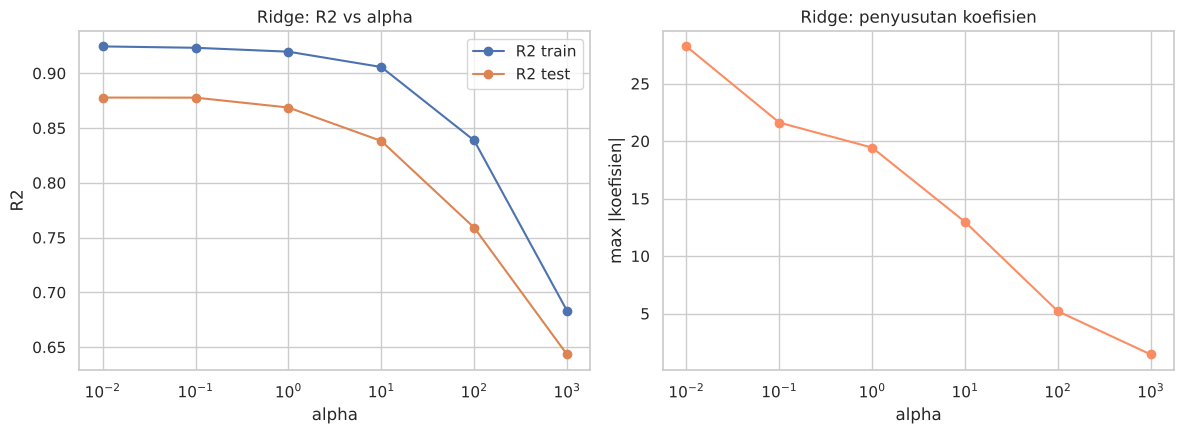

```
     alpha  R2 train  R2 test  RMSE test  max_abs_koef
0     0.01    0.9245   0.8778     6.0386       28.2374
1     0.10    0.9232   0.8777     6.0401       21.6138
2     1.00    0.9197   0.8687     6.2589       19.4326
3    10.00    0.9057   0.8382     6.9481       12.9705
4   100.00    0.8386   0.7591     8.4783        5.1957
5  1000.00    0.6832   0.6433    10.3163        1.4346
```

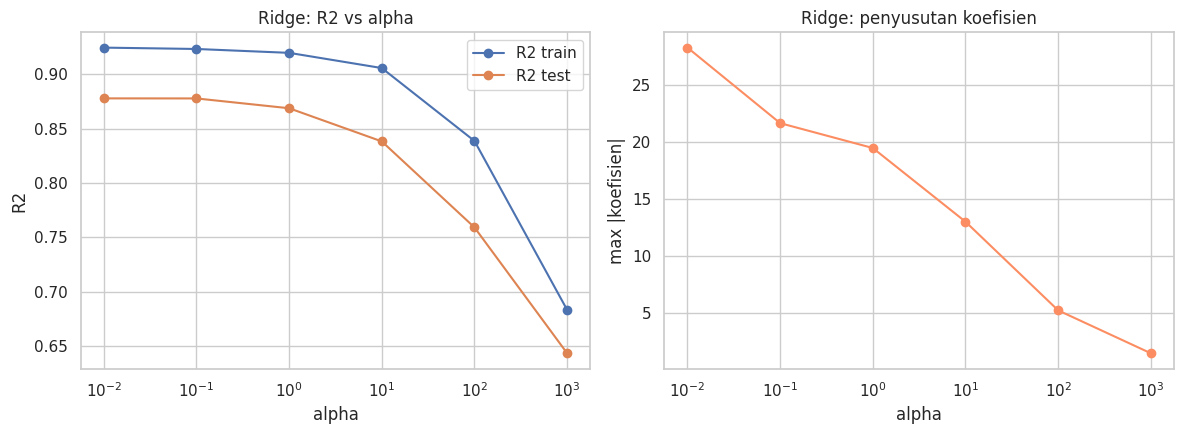

,alpha,R2 train,R2 test,RMSE test,max_abs_koef
0,0.01,0.9245,0.8778,6.0386,28.2374
1,0.10,0.9232,0.8777,6.0401,21.6138
2,1.00,0.9197,0.8687,6.2589,19.4326
3,10.00,0.9057,0.8382,6.9481,12.9705
4,100.00,0.8386,0.7591,8.4783,5.1957
5,1000.00,0.6832,0.6433,10.3163,1.4346


In [74]:
poly3 = Pipeline(
    [
        ("poly", PolynomialFeatures(3)),
    ]
)
X_train_p3 = poly3.fit(X_train_scaled).transform(X_train_scaled)
X_test_p3 = poly3.transform(X_test_scaled)

ridge_rows = []
for alpha in [0.01,0.1,1,10,100,1000]:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_p3, y_train)
    ridge_rows.append({
        "alpha": alpha,
        'R2 train': r2_score(y_train , ridge.predict(X_train_p3)),
        'R2 test': r2_score(y_test , ridge.predict(X_test_p3)),
        'RMSE test': mean_squared_error(y_test, ridge.predict(X_test_p3))**0.5,
        "max_abs_koef": np.abs(ridge.coef_).max(),
    })
ridge_df = pd.DataFrame(ridge_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogx(ridge_df['alpha'], ridge_df['R2 train'], marker='o', label='R2 train')
axes[0].semilogx(ridge_df['alpha'], ridge_df['R2 test'], marker='o', label='R2 test')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('R2')
axes[0].set_title('Ridge: R2 vs alpha')
axes[0].legend()
axes[1].semilogx(ridge_df['alpha'], ridge_df['max_abs_koef'], marker='o', color='#fc8d62')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('max |koefisien|')
axes[1].set_title('Ridge: penyusutan koefisien')
plt.tight_layout()
plt.show()
ridge_df.round(4)

## Soal 13 : Lasso Regression: Pengaruh Alpha
Fitur polynomial `degree=2` sudah disediakan. Lengkapi kode untuk melatih `Lasso` (`max_iter=20000`) dengan setiap nilai `alpha`, lalu hitung R² test dan **jumlah koefisien yang bernilai tepat 0** (fitur yang dibuang oleh Lasso).

**Output referensi:**

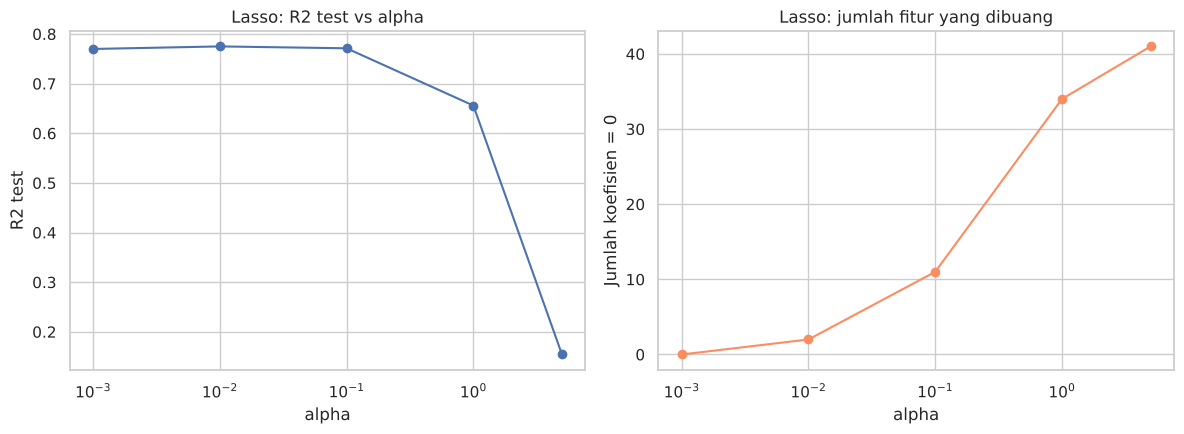

```
   alpha  R2 train  R2 test  koef_nol  total_koef
0  0.001    0.8094   0.7699         0          44
1  0.010    0.8060   0.7750         2          44
2  0.100    0.7923   0.7712        11          44
3  1.000    0.6915   0.6558        34          44
4  5.000    0.1813   0.1543        41          44
```

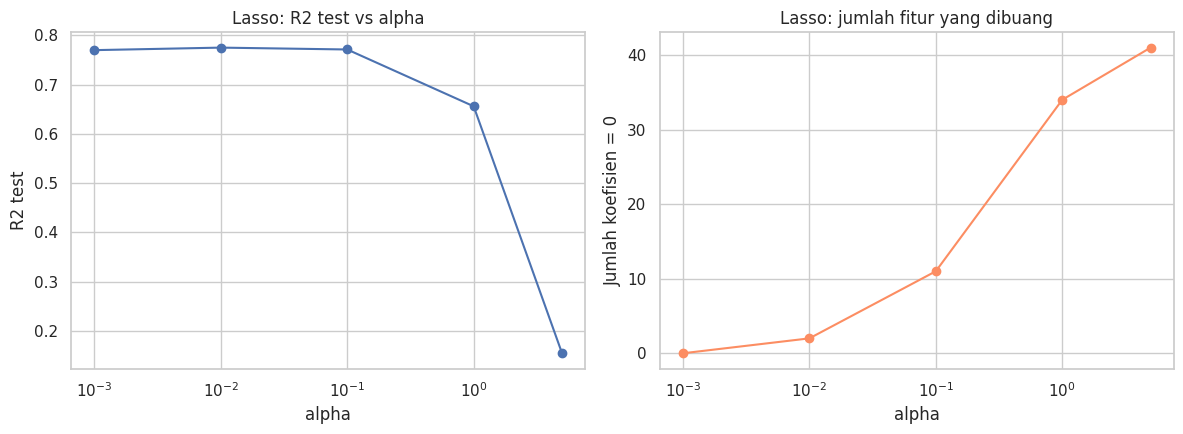

,alpha,R2 train,R2 test,koef_nol,total_koef
0,0.001,0.8094,0.7699,0,44
1,0.010,0.8060,0.7750,2,44
2,0.100,0.7923,0.7712,11,44
3,1.000,0.6915,0.6558,34,44
4,5.000,0.1813,0.1543,41,44


In [75]:
poly2 = Pipeline(
    [
        ("poly", PolynomialFeatures(2, include_bias=False)),
    ]
)
X_train_p2 = poly2.fit(X_train_scaled).transform(X_train_scaled)
X_test_p2 = poly2.transform(X_test_scaled)

lasso_rows = []
for alpha in [0.001,0.01,0.1,1,5]:
    lasso = Lasso(alpha=alpha, max_iter=20000, random_state=RANDOM_STATE)
    lasso.fit(X_train_p2,y_train)
    
    count = 0
    for x in lasso.coef_:
        if x == 0:
            count+=1
    
    lasso_rows.append({
        "alpha": alpha,
        'R2 train': r2_score(y_train , lasso.predict(X_train_p2)),
        'R2 test': r2_score(y_test , lasso.predict(X_test_p2)),
        "koef_nol": count,
        "total_koef": len(lasso.coef_),
    })
lasso_df = pd.DataFrame(lasso_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogx(lasso_df['alpha'], lasso_df['R2 test'], marker='o')
axes[0].set_xlabel('alpha')
axes[0].set_ylabel('R2 test')
axes[0].set_title('Lasso: R2 test vs alpha')
axes[1].semilogx(lasso_df['alpha'], lasso_df['koef_nol'], marker='o', color='#fc8d62')
axes[1].set_xlabel('alpha')
axes[1].set_ylabel('Jumlah koefisien = 0')
axes[1].set_title('Lasso: jumlah fitur yang dibuang')
plt.tight_layout()
plt.show()
lasso_df.round(4)

## Soal 14 : Decision Tree Regressor: Criterion dan Max Depth
Lengkapi kode untuk melatih `DecisionTreeRegressor` dengan setiap kombinasi `criterion` dan `max_depth`. Gunakan `X_train` (tanpa scaling). Visualisasi salah satu pohon sudah disediakan.

**Output referensi:**

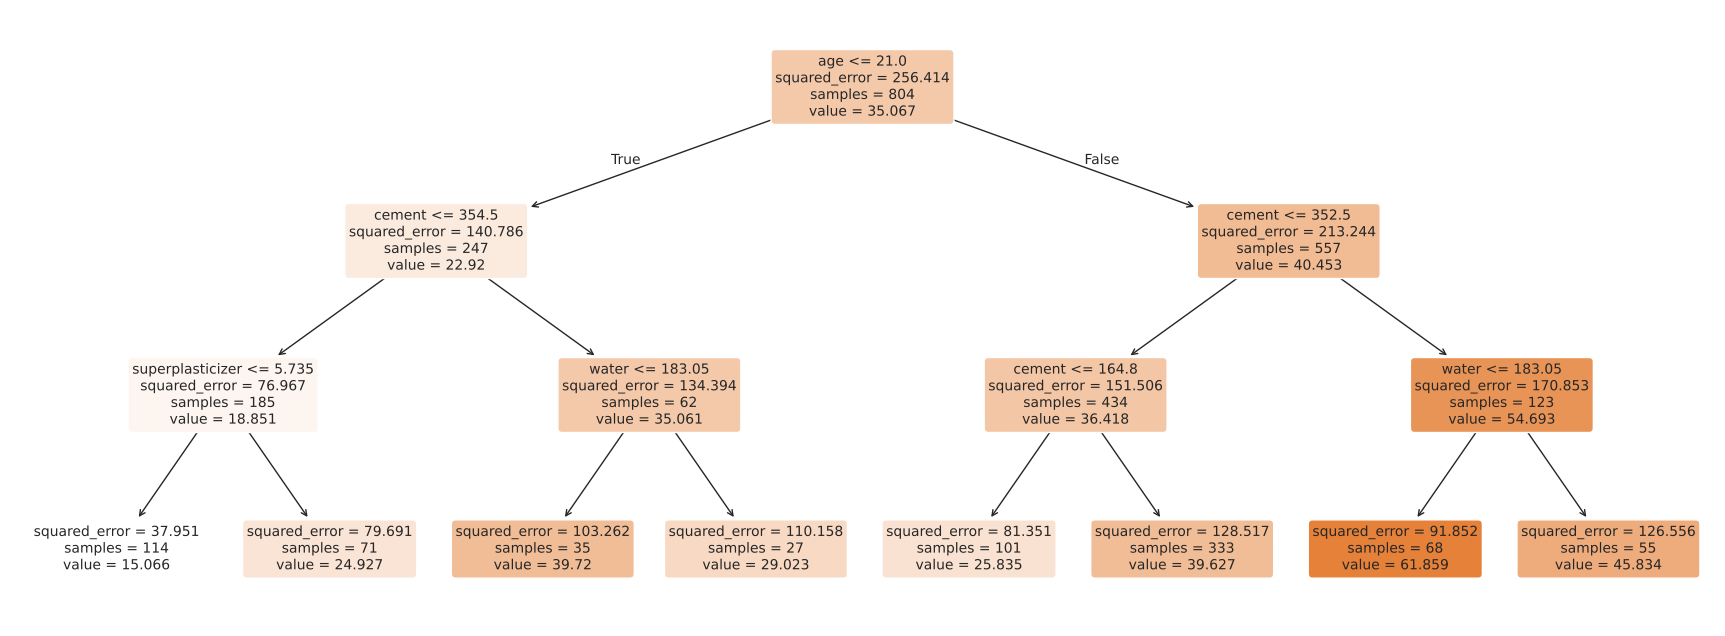

```
        criterion max_depth  R2 train  R2 test
0   squared_error         2    0.4696   0.4418
1   squared_error         4    0.7161   0.6688
2   squared_error         6    0.8658   0.7936
3   squared_error         8    0.9436   0.8350
4   squared_error      None    0.9972   0.8664
5  absolute_error         2    0.4674   0.4436
6  absolute_error         4    0.6949   0.6349
7  absolute_error         6    0.8568   0.7902
8  absolute_error         8    0.9434   0.8653
9  absolute_error      None    0.9972   0.8420
```

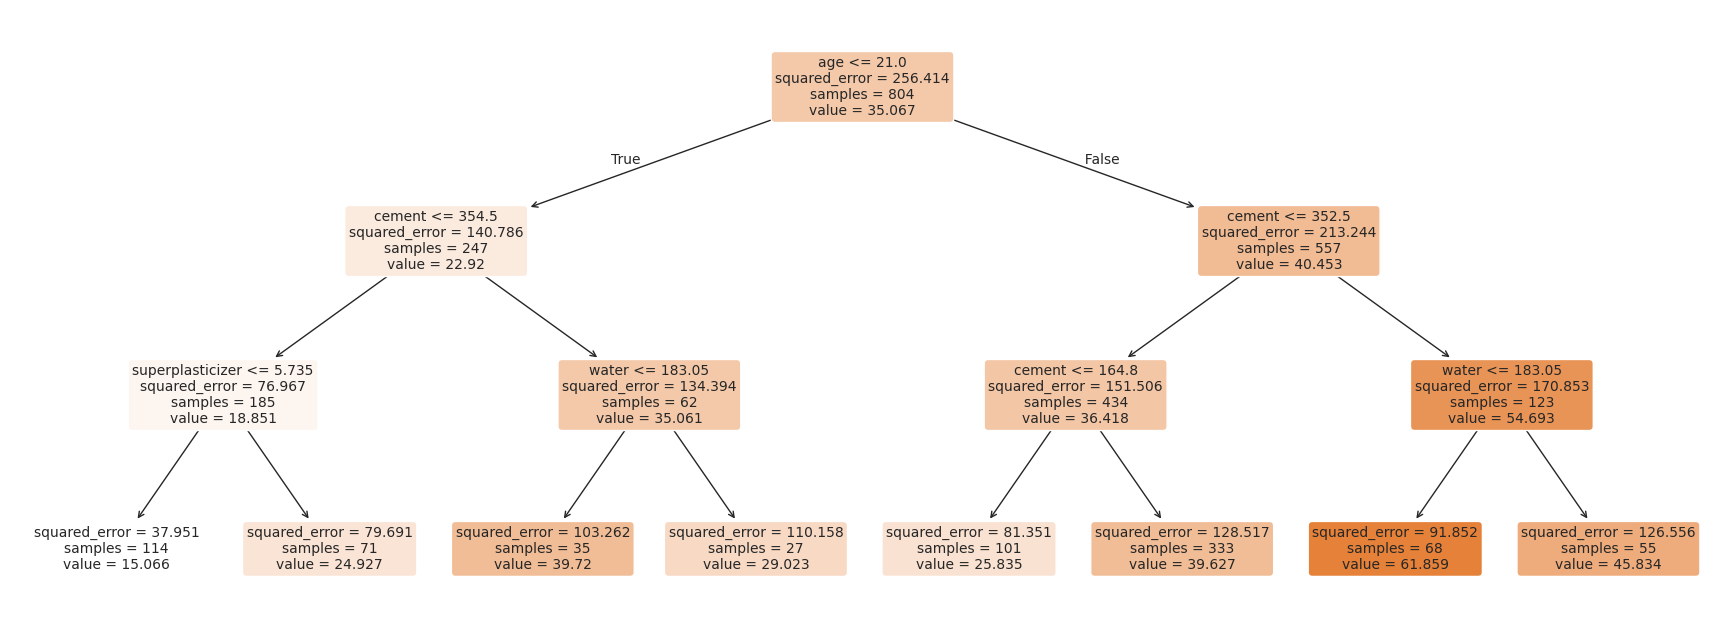

,criterion,max_depth,R2 train,R2 test
0,squared_error,2.0,0.4696,0.4418
1,squared_error,4.0,0.7161,0.6688
2,squared_error,6.0,0.8658,0.7936
3,squared_error,8.0,0.9436,0.8350
4,squared_error,NaN,0.9972,0.8664
5,absolute_error,2.0,0.4674,0.4436
6,absolute_error,4.0,0.6949,0.6349
7,absolute_error,6.0,0.8568,0.7888
8,absolute_error,8.0,0.9436,0.8579
9,absolute_error,NaN,0.9972,0.8553


In [76]:
dt_rows = []
for criterion in ["squared_error", "absolute_error"]:
    for depth in [2,4,6,8,None]:
        dt = DecisionTreeRegressor(criterion=criterion, max_depth=depth, random_state=RANDOM_STATE)
        dt.fit(X_train, y_train)
        dt_rows.append({
            "criterion": criterion,
            "max_depth": depth,
            'R2 train': r2_score(y_train , dt.predict(X_train)),
            'R2 test': r2_score(y_test , dt.predict(X_test)),
        })
dt_df = pd.DataFrame(dt_rows)

# visualisasi pohon (criterion squared_error, max_depth=3)
dt_vis = DecisionTreeRegressor(criterion="squared_error", max_depth=3, random_state=RANDOM_STATE).fit(X_train,y_train)
plt.figure(figsize=(22, 8))
plot_tree(dt_vis, feature_names=feature_names, filled=True, rounded=True, fontsize=10)
plt.show()
dt_df.round(4)

## Soal 15 : SVR: Kernel dan Parameter C
Lengkapi kode untuk melatih `SVR` dengan setiap kombinasi `kernel` dan `C`, lalu catat R² test dan jumlah *support vector*. Gunakan data yang sudah discaling.

**Output referensi:**

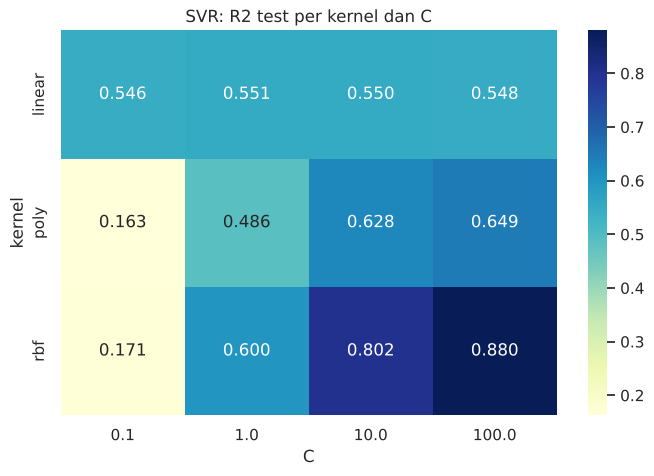

```
    kernel      C  R2 test  jumlah_SV
0   linear    0.1   0.5456        798
1   linear    1.0   0.5506        801
2   linear   10.0   0.5504        798
3   linear  100.0   0.5485        795
4     poly    0.1   0.1627        799
5     poly    1.0   0.4859        792
6     poly   10.0   0.6280        793
7     poly  100.0   0.6489        787
8      rbf    0.1   0.1706        797
9      rbf    1.0   0.5999        798
10     rbf   10.0   0.8017        784
11     rbf  100.0   0.8803        773
```

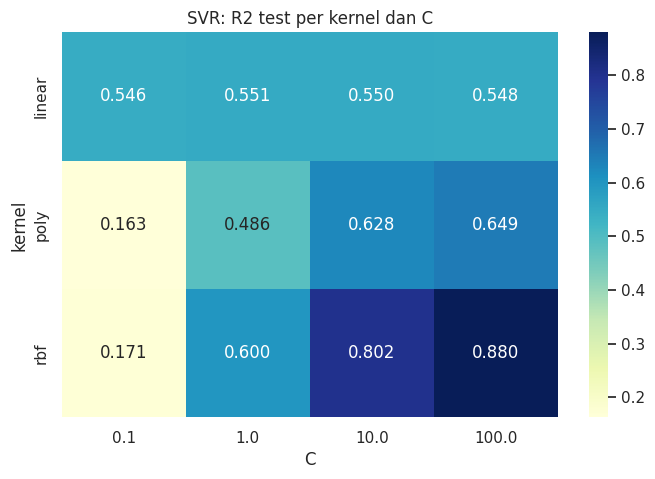

,kernel,C,R2 test,jumlah_SV
0,linear,0.1,0.5456,798
1,linear,1.0,0.5506,801
2,linear,10.0,0.5504,798
3,linear,100.0,0.5485,795
4,poly,0.1,0.1627,799
5,poly,1.0,0.4859,792
6,poly,10.0,0.6280,793
7,poly,100.0,0.6489,787
8,rbf,0.1,0.1706,797
9,rbf,1.0,0.5999,798


In [77]:
svr_rows = []
for kernel in ["linear", "poly", "rbf"]:
    for C in [0.1,1,10,100]:
        svr = SVR(C=C, kernel=kernel)
        svr.fit(X_train_scaled, y_train)
        svr_rows.append({
            "kernel": kernel,
            "C": C,
            "R2 test": r2_score(y_test , svr.predict(X_test_scaled)),
            "jumlah_SV": len(svr.support_vectors_),
        })
svr_df = pd.DataFrame(svr_rows)

plt.figure(figsize=(8, 5))
sns.heatmap(svr_df.pivot(index='kernel', columns='C', values='R2 test'),
            annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('SVR: R2 test per kernel dan C')
plt.show()
svr_df.round(4)

## Soal 16 : Evaluasi dan Perbandingan Model
Empat model berikut sudah dikonfigurasi dari hasil eksplorasi sebelumnya. Lengkapi kode untuk menghitung prediksi, *residual* (`actual - prediksi`), dan RMSE. Plot residual vs prediksi sudah disediakan.

**Output referensi:**

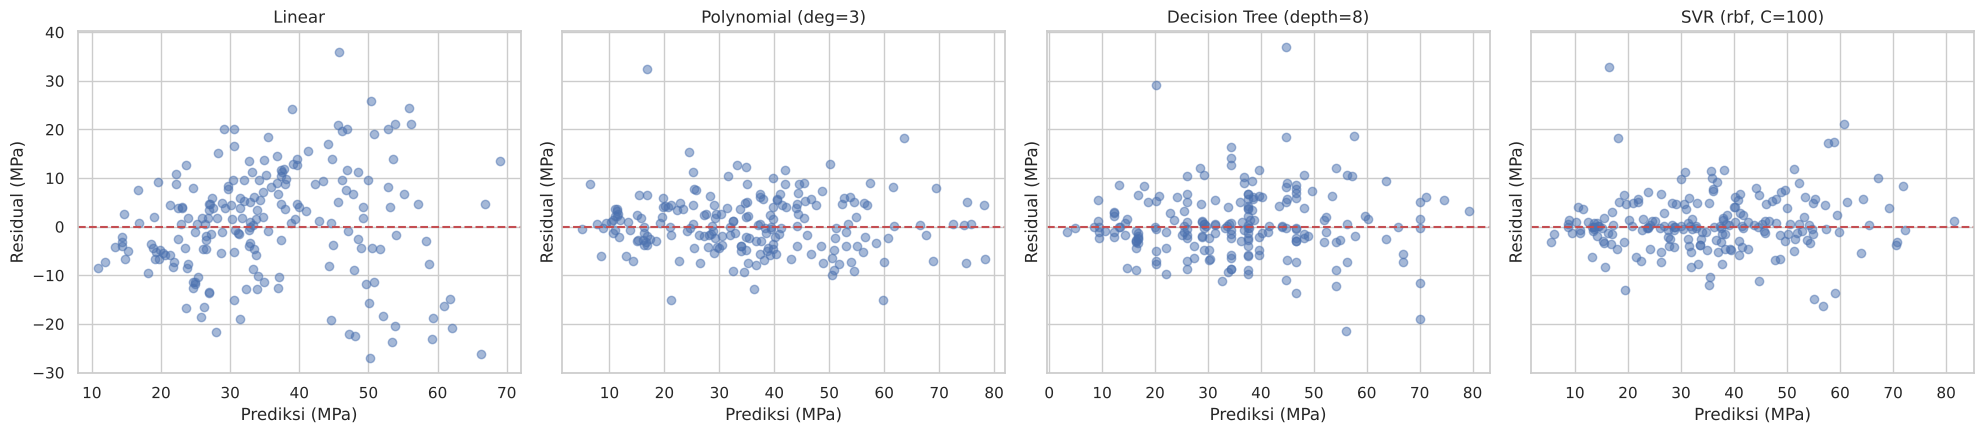

```
                     model     MAE     RMSE      R2
0                   Linear  8.8960  11.1922  0.5801
1       Polynomial (deg=3)  4.5020   5.9484  0.8814
2  Decision Tree (depth=8)  4.8993   7.0160  0.8350
3         SVR (rbf, C=100)  4.0228   5.9765  0.8803
```

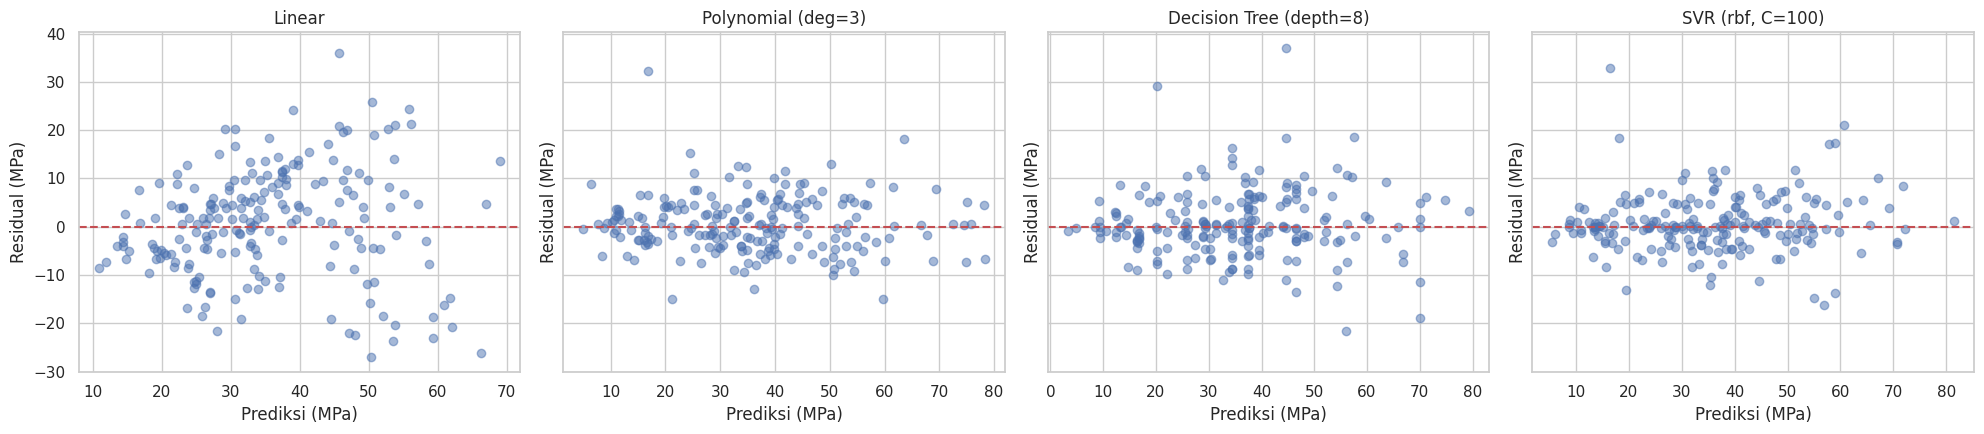

,model,MAE,RMSE,R2
0,Linear,8.8960,11.1922,0.5801
1,Polynomial (deg=3),4.5020,5.9484,0.8814
2,Decision Tree (depth=8),4.8993,7.0160,0.8350
3,"SVR (rbf, C=100)",4.0228,5.9765,0.8803


In [78]:
from sklearn.pipeline import make_pipeline

models = {
    'Linear': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Polynomial (deg=3)': (make_pipeline(PolynomialFeatures(3), LinearRegression()), X_train_scaled, X_test_scaled),
    'Decision Tree (depth=8)': (DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE), X_train, X_test),
    'SVR (rbf, C=100)': (SVR(kernel='rbf', C=100), X_train_scaled, X_test_scaled),
}

metric_rows = []
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, (name, (model, X_tr, X_te)) in zip(axes, models.items()):
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    residual = y_test-y_pred
    ax.scatter(y_pred, residual, alpha=0.5)
    ax.axhline(0, color='r', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Prediksi (MPa)')
    ax.set_ylabel('Residual (MPa)')
    metric_rows.append({
        'model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': mean_squared_error(y_test, y_pred)**0.5,
        'R2': r2_score(y_test, y_pred),
    })
plt.tight_layout()
plt.show()
pd.DataFrame(metric_rows).round(4)

---
# Bagian C : Clustering (Soal 17–23)

### Dataset: Wine Recognition (UCI)
Sumber: UCI Machine Learning Repository (salinan di `sklearn.datasets.load_wine`).

Upload `wine_dataset.csv` melalui **Add Input → Upload → New Dataset** di Kaggle Notebook.

178 sampel anggur dari 3 cultivar di Italia, dengan 13 fitur hasil analisis kimia (alcohol, malic_acid, flavanoids, proline, dll.). Kolom `cultivar` **tidak dipakai untuk membentuk cluster**.

## Soal 17 : Import Library Model Clustering
Lengkapi import `sklearn` untuk semua komponen yang dipakai pada Soal 18–23: PCA, K-Means, Agglomerative (Hierarchical) Clustering, DBSCAN, BIRCH, serta metrik silhouette score, silhouette samples, Davies-Bouldin, Calinski-Harabasz, dan Adjusted Rand Index.

Sel ini tidak menghasilkan output. Jawaban dianggap benar jika sel berjalan tanpa error dan seluruh soal berikutnya pada bagian ini dapat dijalankan.

In [79]:
# PCA
from sklearn.decomposition import PCA
# K-Means, Agglomerative (Hierarchical), DBSCAN, BIRCH
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch
# Metrik: silhouette score, silhouette samples, Davies-Bouldin, Calinski-Harabasz, Adjusted Rand Index
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

## C.1 Data Loading

In [80]:
DATA_PATH = next(iter(glob.glob('/kaggle/input/datasets/farelfebryan/dataset-ets-praktikum-ml-rka-2026/Wine_Dataset.csv', recursive=True)), 'wine_dataset.csv')
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## C.2 Exploratory Data Analysis

In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  culti

In [82]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [83]:
print('Missing value:', df.isna().sum().sum())
print('Duplikat     :', df.duplicated().sum())
print(df['cultivar'].value_counts().sort_index())

Missing value: 0
Duplikat     : 0
cultivar
0    59
1    71
2    48
Name: count, dtype: int64


Kolom `cultivar` adalah jenis anggur (cultivar) asli: 0, 1, atau 2. Pada clustering **label ini tidak dipakai untuk membentuk cluster**; ia hanya disimpan sebagai pembanding eksternal (ARI) pada Soal 19, 21, dan 23.

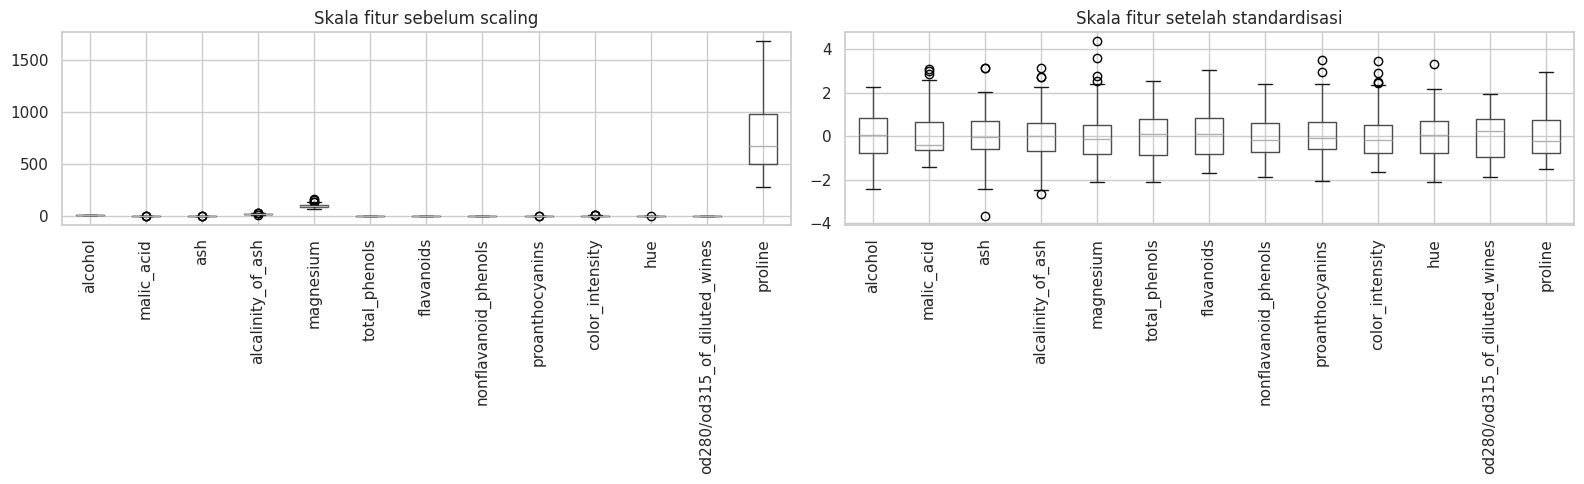

In [84]:
features = df.columns.drop('cultivar').tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df[features].boxplot(ax=axes[0], rot=90)
axes[0].set_title('Skala fitur sebelum scaling')
(df[features] - df[features].mean()).div(df[features].std()).boxplot(ax=axes[1], rot=90)
axes[1].set_title('Skala fitur setelah standardisasi')
plt.tight_layout()
plt.show()

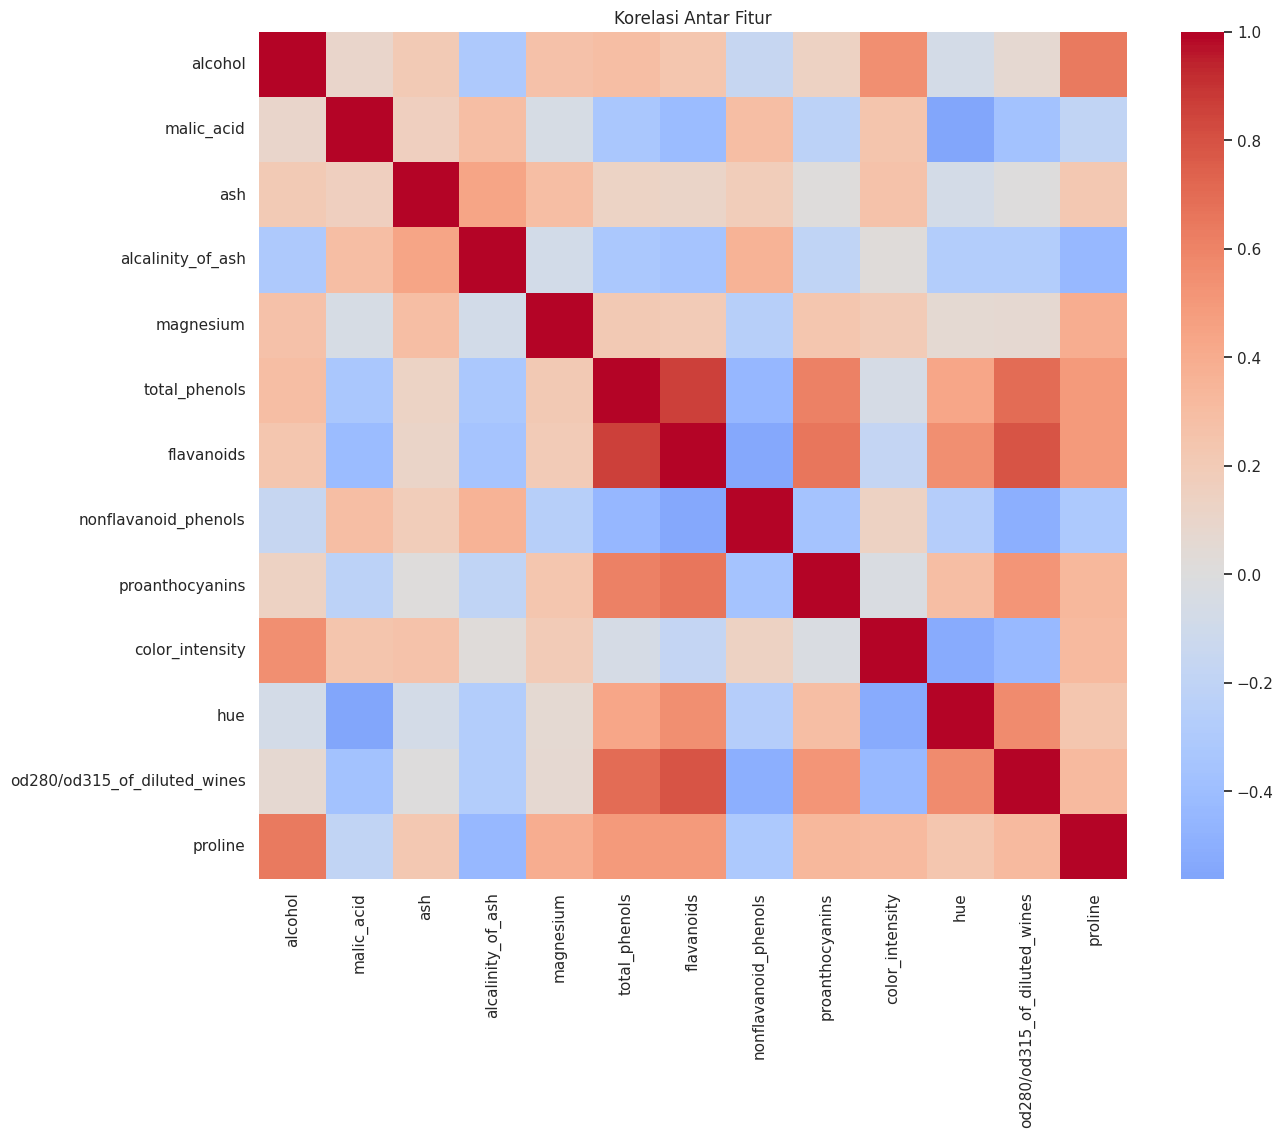

In [85]:
plt.figure(figsize=(14, 11))
sns.heatmap(df[features].corr(), cmap='coolwarm', center=0)
plt.title('Korelasi Antar Fitur')
plt.show()

## C.3 Preprocessing

In [86]:
X = df[features]
y_true = df['cultivar']   # hanya untuk evaluasi eksternal

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('X_scaled:', X_scaled.shape)

X_scaled: (178, 13)


| Variabel | Isi | Dipakai untuk |
|----------|-----|---------------|
| `X_scaled` | 13 fitur kimia + StandardScaler (*numpy array*) | Semua model clustering |
| `y_true` | Label cultivar asli (0/1/2) | **Hanya** evaluasi eksternal (ARI) |

## C.4 Soal Clustering

## Soal 18 : K-Means: Menentukan Jumlah Cluster (K)
Lengkapi kode untuk melatih `KMeans` (`n_init=10`) dengan setiap nilai `K` (2–8), lalu simpan **inertia** dan **silhouette score** pada data `X_scaled`.

**Output referensi:**

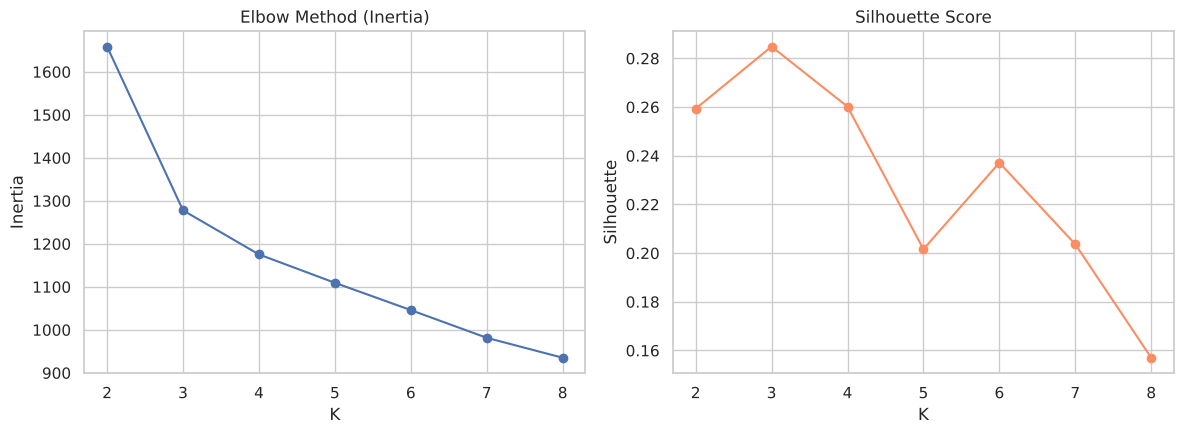

```
   k    inertia  silhouette
0  2  1658.7589      0.2593
1  3  1277.9285      0.2849
2  4  1175.4283      0.2602
3  5  1109.5127      0.2016
4  6  1046.0023      0.2372
5  7   981.5952      0.2036
6  8   935.2012      0.1570
```

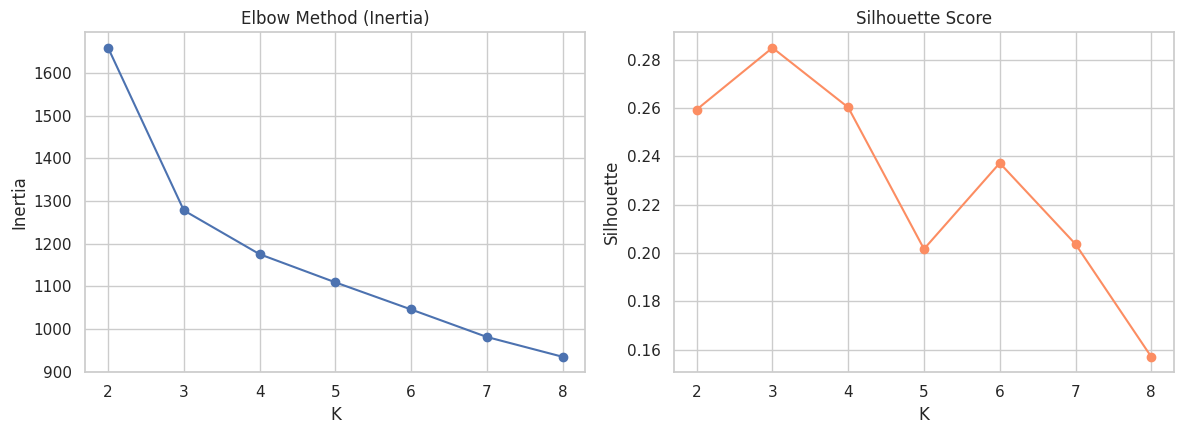

,k,inertia,silhouette
0,2,1658.7589,0.2593
1,3,1277.9285,0.2849
2,4,1175.4283,0.2602
3,5,1109.5127,0.2016
4,6,1046.0023,0.2372
5,7,981.5952,0.2036
6,8,935.2012,0.1570


In [87]:
k_values = list(range(2, 9))
inertia, sil = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(k_values, inertia, marker='o')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')
axes[1].plot(k_values, sil, marker='o', color='#fc8d62')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()
pd.DataFrame({'k': k_values, 'inertia': inertia, 'silhouette': sil}).round(4)

## Soal 19 : Hierarchical Clustering: Perbandingan Linkage
Lengkapi kode untuk melatih `AgglomerativeClustering` (`n_clusters=3`) dengan setiap jenis *linkage* (`ward`, `complete`, `average`, `single`), lalu hitung silhouette score. Setelah itu buat *linkage matrix* teknik **single link** dan **Ward**, lalu gambarkan dendrogramnya.

**Output referensi:**

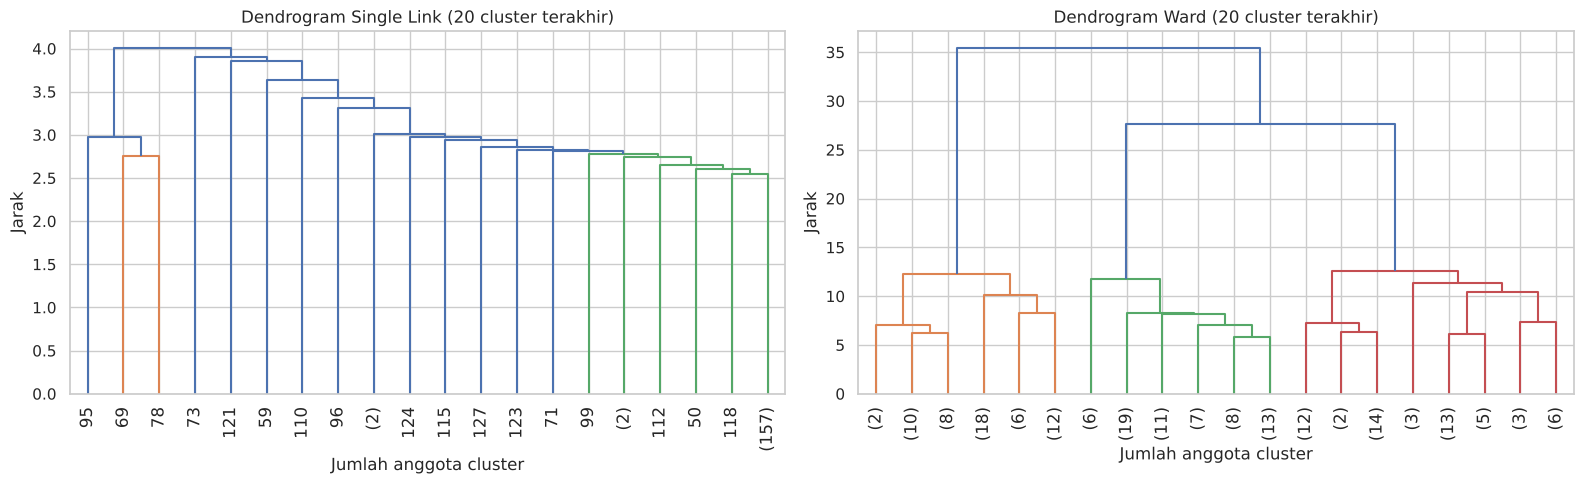

```
    linkage ukuran_cluster  silhouette     ARI
0      ward   [58, 56, 64]      0.2774  0.7899
1  complete   [69, 58, 51]      0.2038  0.5771
2   average    [174, 1, 3]      0.1575 -0.0054
3    single    [174, 3, 1]      0.1827 -0.0068
```

,linkage,ukuran_cluster,silhouette,ARI
0,ward,"[58, 56, 64]",0.2774,0.7899
1,complete,"[69, 58, 51]",0.2038,0.5771
2,average,"[174, 1, 3]",0.1575,-0.0054
3,single,"[174, 3, 1]",0.1827,-0.0068


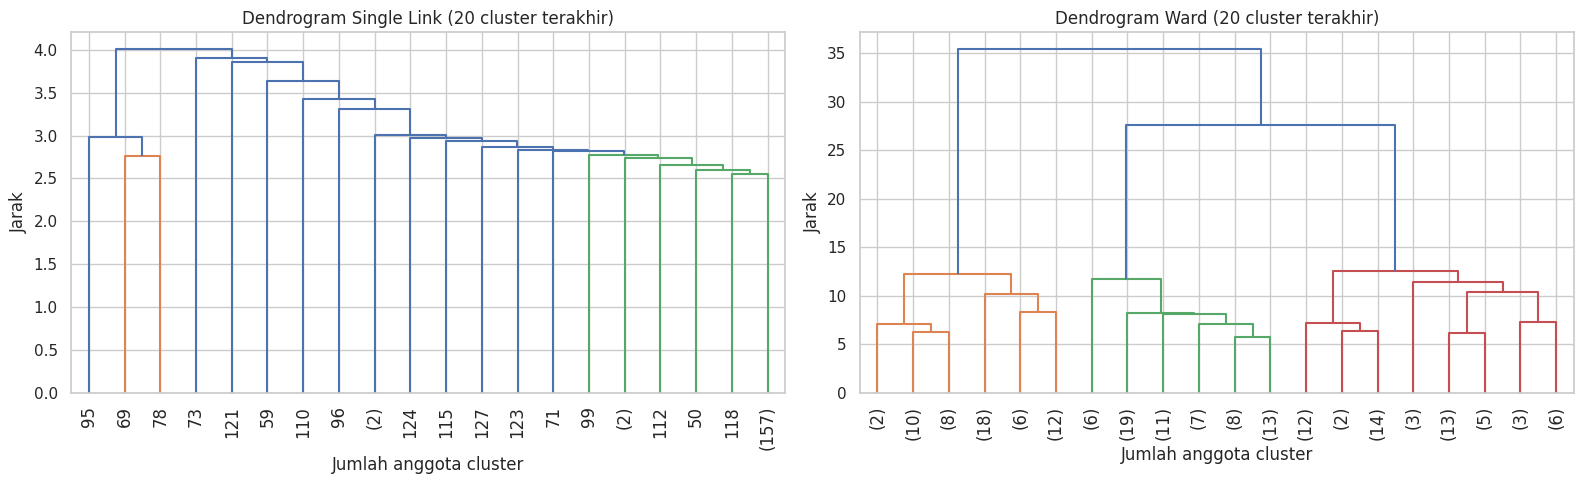

In [88]:
hc_rows = []
for method in ['ward', 'complete', 'average', 'single']:
    hc = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = hc.fit_predict(X_scaled)
    hc_rows.append({
        'linkage': method,
        'ukuran_cluster': np.bincount(labels).tolist(),
        'silhouette': silhouette_score(X_scaled, labels),
        'ARI': adjusted_rand_score(y_true, labels),
    })
display(pd.DataFrame(hc_rows).round(4))

Z_single = hc_linkage(X_scaled, method='single')
Z_ward = hc_linkage(X_scaled, method='ward')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, Z, nama in zip(axes, [Z_single, Z_ward], ['Single Link', 'Ward']):
    dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=90, ax=ax)
    ax.set_title(f'Dendrogram {nama} (20 cluster terakhir)')
    ax.set_xlabel('Jumlah anggota cluster')
    ax.set_ylabel('Jarak')
plt.tight_layout()
plt.show()

## Soal 20 : DBSCAN: Pengaruh `eps` dan `min_samples`
Lengkapi kode untuk melatih `DBSCAN` dengan setiap kombinasi `eps` (1.5–3.0) dan `min_samples` (3, 5). Hitung jumlah cluster (**tidak termasuk noise**, label `-1`) dan jumlah titik noise.

**Output referensi:**

```
   min_samples  eps  n_cluster  n_noise  silhouette
0            3  1.5          8      147      0.3311
1            3  2.0          5       64      0.2113
2            3  2.5          1       23         NaN
3            3  3.0          2        7      0.2392
4            5  1.5          0      178         NaN
5            5  2.0          5       85      0.2405
6            5  2.5          1       24         NaN
7            5  3.0          1       11         NaN
```

In [89]:
db_rows = []
for min_samples in [3, 5]:
    for eps in [1.5, 2.0, 2.5, 3.0]:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_scaled)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        db_rows.append({
            'min_samples': min_samples,
            'eps': eps,
            'n_cluster': n_clusters,
            'n_noise': int((~mask).sum()),
            'silhouette': silhouette_score(X_scaled[mask], labels[mask]) if n_clusters > 1 else np.nan,
        })
pd.DataFrame(db_rows).round(4)

,min_samples,eps,n_cluster,n_noise,silhouette
0,3,1.5,8,147,0.3311
1,3,2.0,5,64,0.2113
2,3,2.5,1,23,NaN
3,3,3.0,2,7,0.2392
4,5,1.5,0,178,NaN
5,5,2.0,5,85,0.2405
6,5,2.5,1,24,NaN
7,5,3.0,1,11,NaN


## Soal 21 : BIRCH: Threshold dan Branching Factor
Lengkapi kode untuk melatih `Birch` (`n_clusters=3`) dengan setiap kombinasi `branching_factor` (10, 50) dan `threshold` (0.5–3.0). Catat jumlah *subcluster* yang terbentuk di CF-Tree (`subcluster_centers_`).

**Output referensi:**

```
   branching_factor  threshold  n_subcluster  silhouette     ARI
0                10        0.5           178      0.2774  0.7899
1                10        1.0           129      0.2757  0.7605
2                10        2.0            31      0.2553  0.6764
3                10        3.0             6      0.1781 -0.0068
4                50        0.5           178      0.2774  0.7899
5                50        1.0           123      0.2731  0.7605
6                50        2.0            27      0.2628  0.7396
7                50        3.0             6      0.1781 -0.0068
```

In [90]:
birch_rows = []
for branching_factor in [10, 50]:
    for threshold in [0.5, 1.0, 2.0, 3.0]:
        birch = Birch(n_clusters=3, threshold=threshold, branching_factor=branching_factor)
        labels = birch.fit_predict(X_scaled)
        birch_rows.append({
            'branching_factor': branching_factor,
            'threshold': threshold,
            'n_subcluster': len(birch.subcluster_centers_),
            'silhouette': silhouette_score(X_scaled, labels),
            'ARI': adjusted_rand_score(y_true, labels),
        })
pd.DataFrame(birch_rows).round(4)

,branching_factor,threshold,n_subcluster,silhouette,ARI
0,10,0.5,178,0.2774,0.7899
1,10,1.0,129,0.2757,0.7605
2,10,2.0,31,0.2553,0.6764
3,10,3.0,6,0.1781,-0.0068
4,50,0.5,178,0.2774,0.7899
5,50,1.0,123,0.2731,0.7605
6,50,2.0,27,0.2628,0.7396
7,50,3.0,6,0.1781,-0.0068


## Soal 22 : Reduksi Dimensi: PCA
Lengkapi kode untuk melakukan PCA pada `X_scaled`: hitung explained variance kumulatif, tentukan jumlah komponen minimum untuk menjelaskan ≥ 90% varians, dan proyeksikan data ke 2 dimensi untuk visualisasi hasil K-Means (`K=3`).

**Output referensi:**

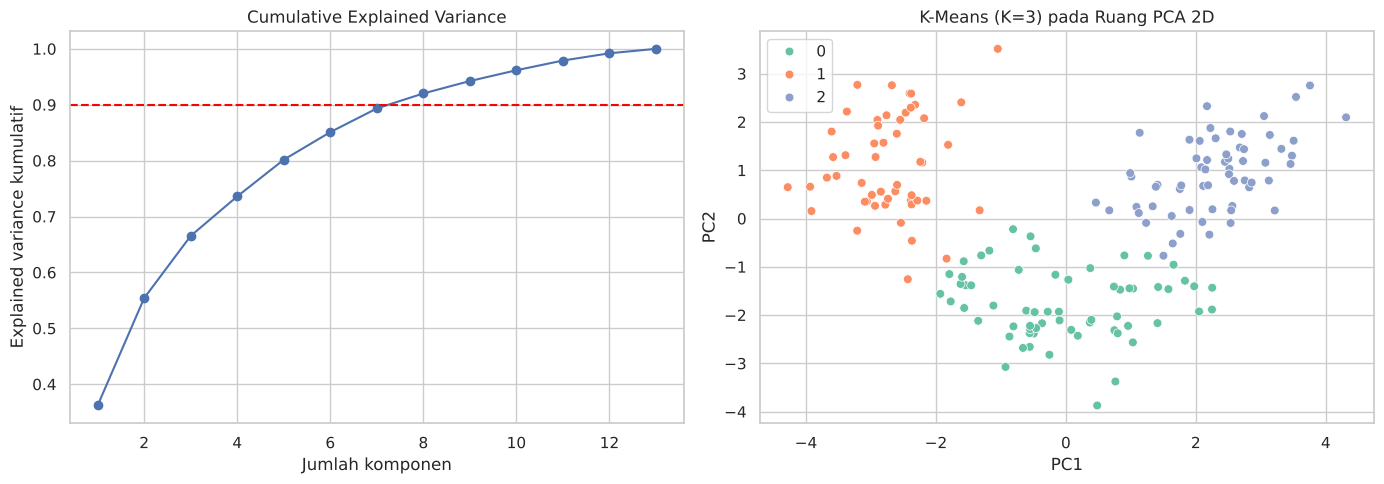

```
Jumlah komponen untuk menjelaskan >= 90% varians: 8

   komponen  explained_variance_ratio  kumulatif
0         1                    0.3620     0.3620
1         2                    0.1921     0.5541
2         3                    0.1112     0.6653
3         4                    0.0707     0.7360
4         5                    0.0656     0.8016
```

Jumlah komponen untuk menjelaskan >= 90% varians: 8


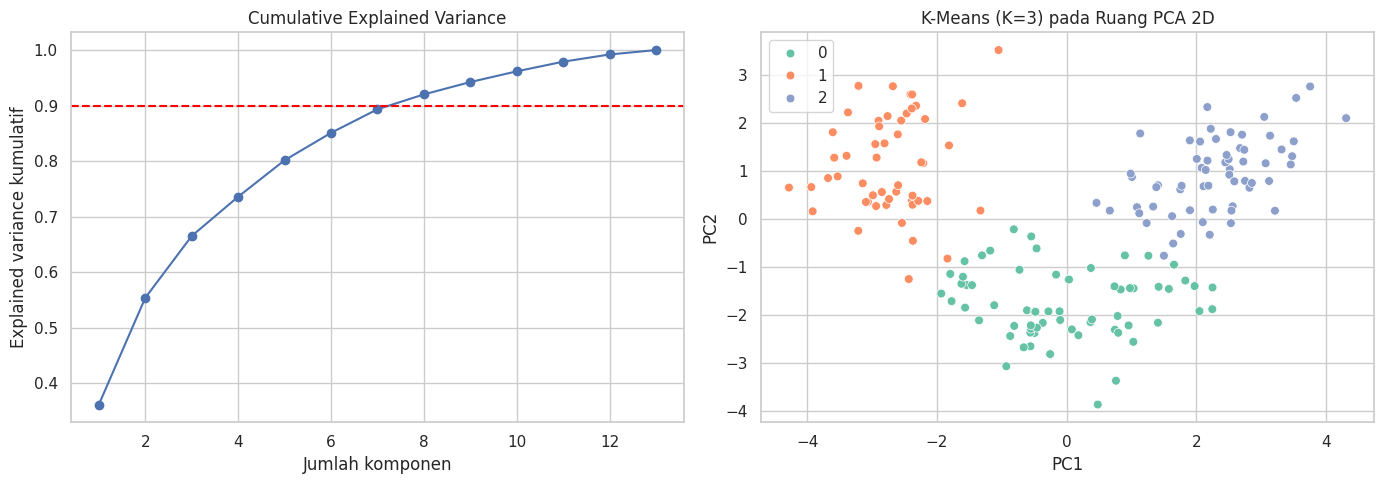

,komponen,explained_variance_ratio,kumulatif
0,1,0.3620,0.3620
1,2,0.1921,0.5541
2,3,0.1112,0.6653
3,4,0.0707,0.7360
4,5,0.0656,0.8016


In [91]:
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = int(np.argmax(cum_var >= 0.9) + 1)
print(f'Jumlah komponen untuk menjelaskan >= 90% varians: {n_90}')

X_pca = PCA(n_components=2).fit_transform(X_scaled)
cluster_labels = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker='o')
axes[0].axhline(0.9, color='red', linestyle='--')
axes[0].set_xlabel('Jumlah komponen')
axes[0].set_ylabel('Explained variance kumulatif')
axes[0].set_title('Cumulative Explained Variance')
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette='Set2', s=40, ax=axes[1])
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('K-Means (K=3) pada Ruang PCA 2D')
plt.tight_layout()
plt.show()
pd.DataFrame({'komponen': range(1, 6), 'explained_variance_ratio': pca_full.explained_variance_ratio_[:5],
              'kumulatif': cum_var[:5]}).round(4)

## Soal 23 : Evaluasi Metrik Clustering
Lengkapi kode untuk menghitung *silhouette per sampel* (untuk plot silhouette), serta **silhouette score**, **Davies-Bouldin index**, **Calinski-Harabasz index**, dan **Adjusted Rand Index** (terhadap label `cultivar` asli sebagai pembanding eksternal) dari ketiga model berikut.

**Output referensi:**

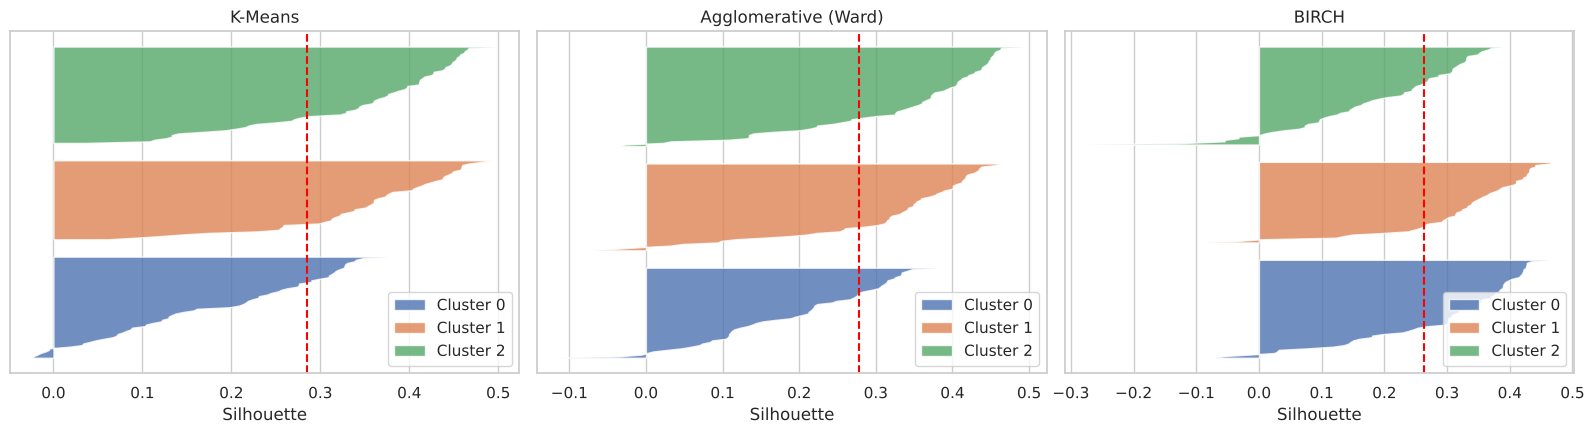

```
                  model  silhouette  davies_bouldin  calinski_harabasz  ARI (vs cultivar)
0               K-Means      0.2849          1.3892            70.9400             0.8975
1  Agglomerative (Ward)      0.2774          1.4186            67.6475             0.7899
2                 BIRCH      0.2628          1.4464            66.3552             0.7396
```

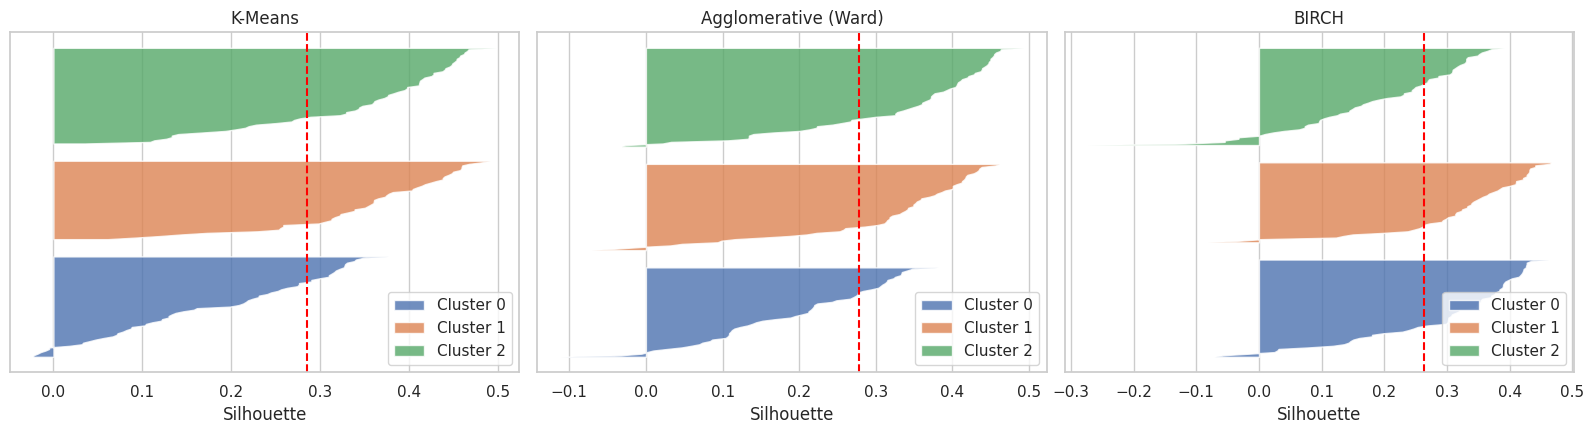

,model,silhouette,davies_bouldin,calinski_harabasz,ARI (vs cultivar)
0,K-Means,0.2849,1.3892,70.9400,0.8975
1,Agglomerative (Ward),0.2774,1.4186,67.6475,0.7899
2,BIRCH,0.2628,1.4464,66.3552,0.7396


In [92]:
models = {
    'K-Means': KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE),
    'Agglomerative (Ward)': AgglomerativeClustering(n_clusters=3, linkage='ward'),
    'BIRCH': Birch(threshold=2.0, branching_factor=50, n_clusters=3),
}

eval_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    labels = model.fit_predict(X_scaled)
    sample_sil = silhouette_samples(X_scaled, labels)
    y_lower = 10
    for c in range(3):
        c_sil = np.sort(sample_sil[labels == c])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(c_sil)), 0, c_sil, alpha=0.8, label=f'Cluster {c}')
        y_lower += len(c_sil) + 10
    ax.axvline(sample_sil.mean(), color='red', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Silhouette')
    ax.set_yticks([])
    ax.legend(loc='lower right')
    eval_rows.append({
        'model': name,
        'silhouette': silhouette_score(X_scaled, labels),
        'davies_bouldin': davies_bouldin_score(X_scaled, labels),
        'calinski_harabasz': calinski_harabasz_score(X_scaled, labels),
        'ARI (vs cultivar)': adjusted_rand_score(y_true, labels),
    })
plt.tight_layout()
plt.show()
pd.DataFrame(eval_rows).round(4)